In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/ChestXRay2017.zip"
extract_path = "/content/extracted_images"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(" Extraction completed")

 Extraction completed


In [ ]:
DATASET_PATH = "/content/extracted_images/chest_xray"

In [ ]:
print(tf.__version__)

IMG_SIZE = 64
BATCH_SIZE = 32
LATENT_DIM = 100

2.20.0


PNEUMONIA IMAGES LOAD

In [ ]:
PNEUMONIA_PATH = os.path.join(
    DATASET_PATH,
    "/content/extracted_images/chest_xray/train",
    "/content/extracted_images/chest_xray/train/PNEUMONIA"
)

image_paths = [
    os.path.join(PNEUMONIA_PATH, f)
    for f in os.listdir(PNEUMONIA_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of Pneumonia images:", len(image_paths))

Number of Pneumonia images: 3883


TENSORFLOW DATASET MAKING

In [ ]:
def load_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=1)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    # Normalize to [-1, 1]
    image = (tf.cast(image, tf.float32) / 127.5) - 1.0

    return image

In [ ]:
dataset = tf.data.Dataset.from_tensor_slices(image_paths)

dataset = dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

dataset = dataset.shuffle(1000)
dataset = dataset.batch(BATCH_SIZE)
dataset = dataset.prefetch(tf.data.AUTOTUNE)

print("Dataset ready")

Dataset ready


GENERATOR ( FROM NOISE IMAGES MAKING SYNTETIC X-RAY)

In [ ]:
def build_generator():

    model = tf.keras.Sequential([

        layers.Dense(
            8 * 8 * 256,
            use_bias=False,
            input_shape=(LATENT_DIM,)
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((8, 8, 256)),

        layers.Conv2DTranspose(
            128,
            kernel_size=4,
            strides=2,
            padding='same',
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            64,
            kernel_size=4,
            strides=2,
            padding='same',
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            32,
            kernel_size=4,
            strides=2,
            padding='same',
            use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2D(
            1,
            kernel_size=3,
            padding='same',
            activation='tanh'
        )
    ])

    return model

In [ ]:
generator = build_generator()
generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16384)          │     1,638,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16384)          │        65,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,393,249 (9.13 MB)

 Trainable params: 2,360,033 (9.00 MB)

 Non-trainable params: 33,216 (129.75 KB)

DISCRIMINATOR( CLASSIFY REAL IMAGES OR GENERATED IMAGES)

In [ ]:
def build_discriminator():

    model = tf.keras.Sequential([

        layers.Conv2D(
            64,
            kernel_size=4,
            strides=2,
            padding='same',
            input_shape=(IMG_SIZE, IMG_SIZE, 1)
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(
            128,
            kernel_size=4,
            strides=2,
            padding='same'
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(
            256,
            kernel_size=4,
            strides=2,
            padding='same'
        ),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),

        layers.Dense(1)
    ])

    return model

In [ ]:
discriminator = build_discriminator()
discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        16,385 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,217 (2.57 MB)

 Trainable params: 673,217 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

LOSS FUNCTON

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

In [ ]:
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

In [ ]:
def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

OPTIMIZERS

In [ ]:
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

TRAINING

In [ ]:
@tf.function
def train_step(images):

    noise = tf.random.normal(
        [BATCH_SIZE, LATENT_DIM]
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        gen_loss = generator_loss(
            fake_output
        )

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

TO SHOW GENERATED IMAGES

In [ ]:
seed = tf.random.normal(
    [16, LATENT_DIM]
)

In [ ]:
def generate_and_show_images(model, epoch):

    predictions = model(
        seed,
        training=False
    )

    predictions = (predictions + 1) / 2.0

    plt.figure(figsize=(8, 8))

    for i in range(16):

        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap='gray'
        )

        plt.axis('off')

    plt.suptitle(
        f"Generated Pneumonia X-rays - Epoch {epoch}"
    )

    plt.show()

GAN TRAINING

Epoch 1/20 Generator Loss: 1.3047 Discriminator Loss: 0.9157


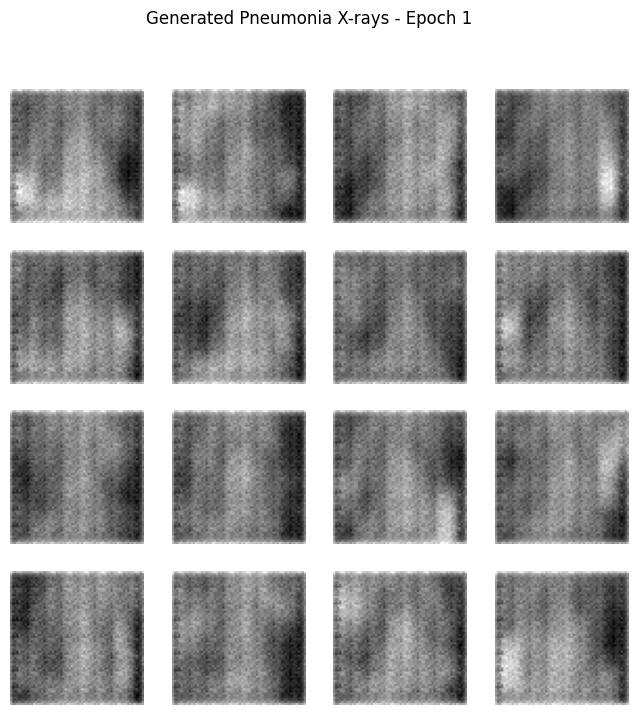

Epoch 2/20 Generator Loss: 0.8718 Discriminator Loss: 1.2035


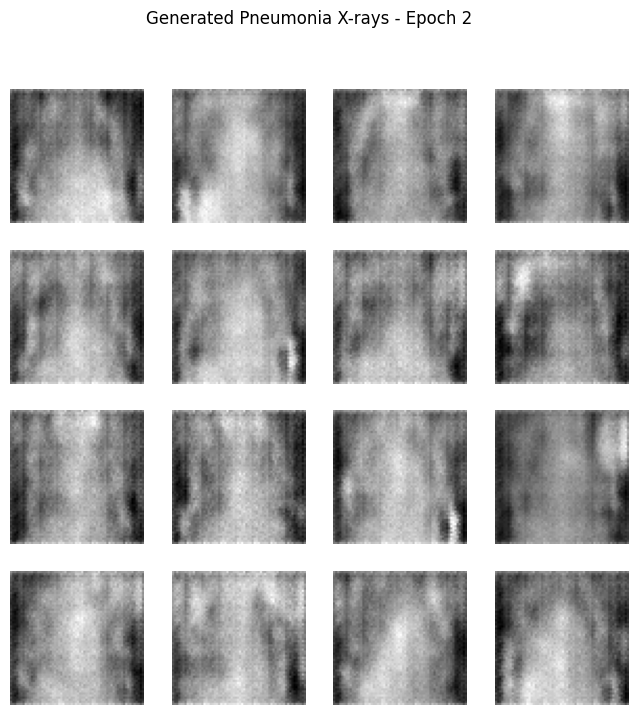

Epoch 3/20 Generator Loss: 0.8657 Discriminator Loss: 1.2166


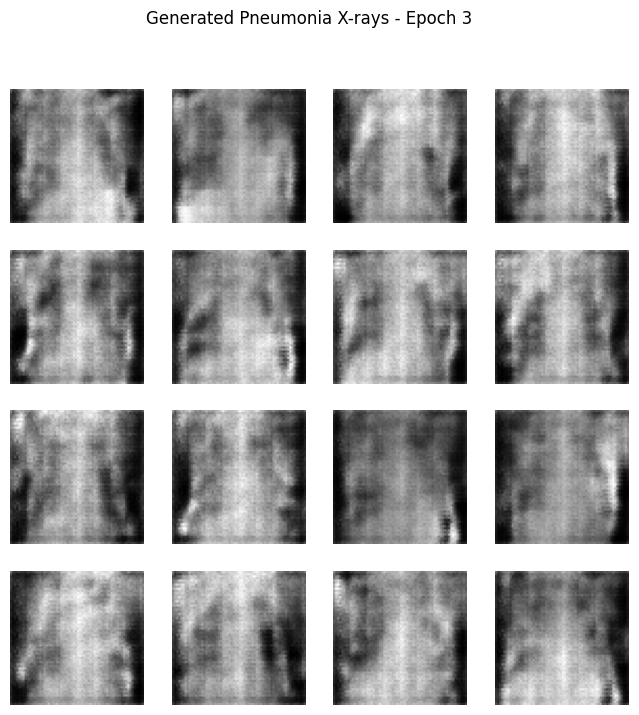

Epoch 4/20 Generator Loss: 0.7475 Discriminator Loss: 1.3036


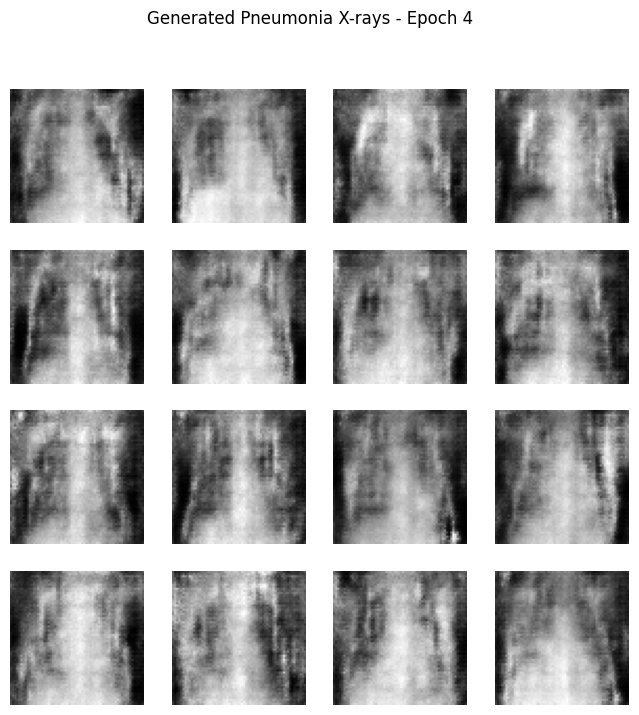

Epoch 5/20 Generator Loss: 0.7479 Discriminator Loss: 1.3335


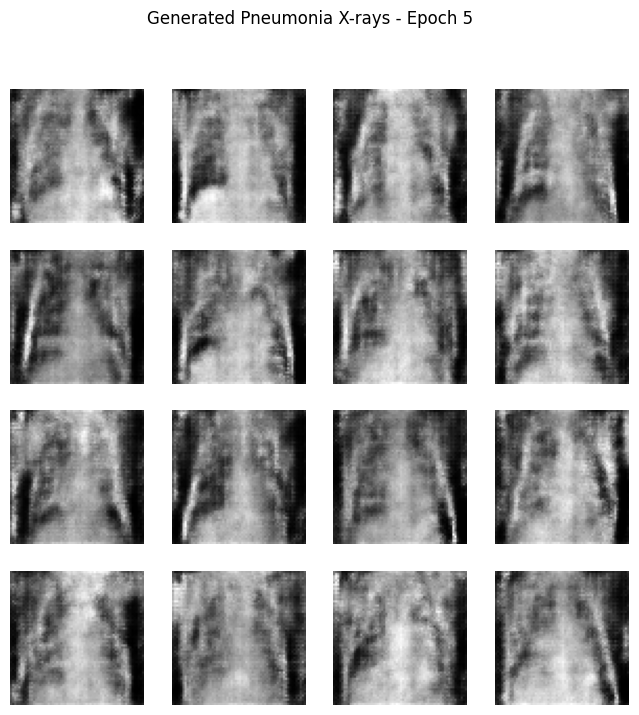

Epoch 6/20 Generator Loss: 0.7462 Discriminator Loss: 1.3256


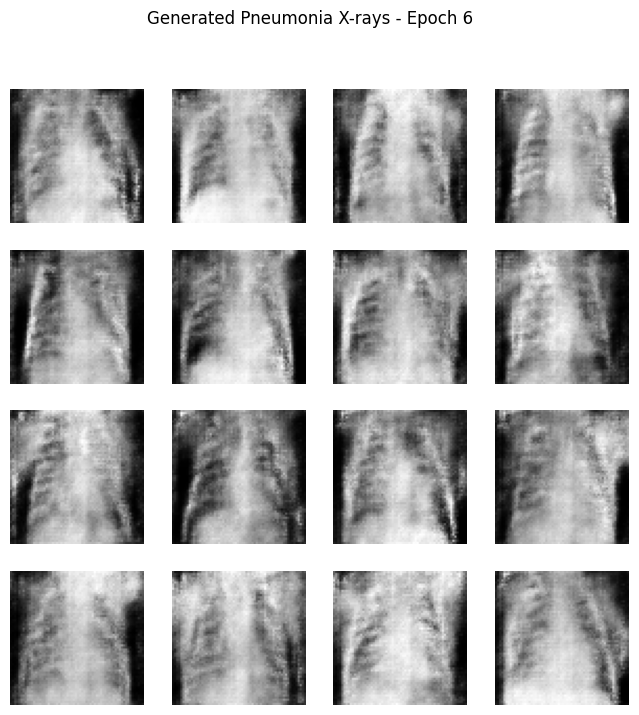

Epoch 7/20 Generator Loss: 0.7459 Discriminator Loss: 1.3096


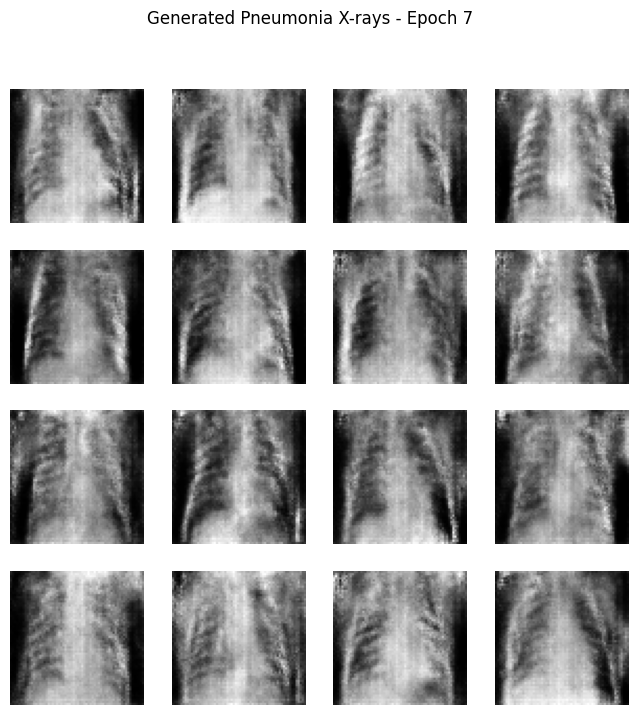

Epoch 8/20 Generator Loss: 1.1094 Discriminator Loss: 1.1538


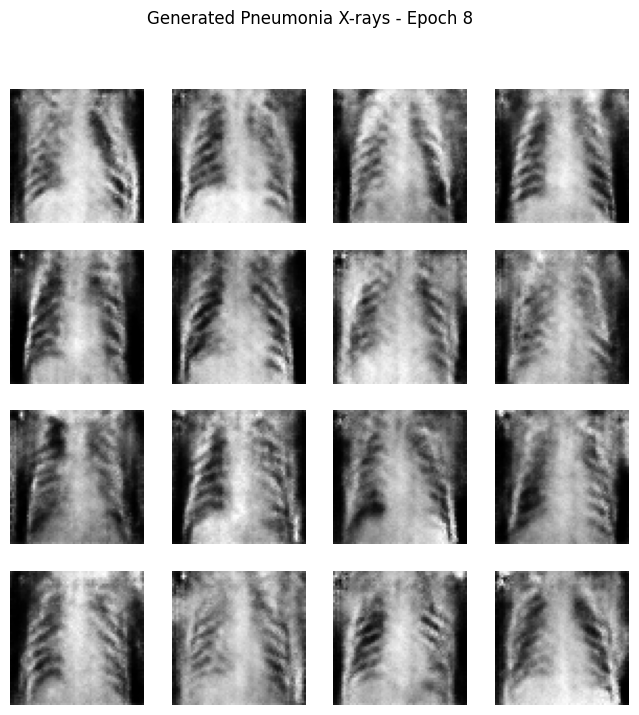

Epoch 9/20 Generator Loss: 0.7470 Discriminator Loss: 1.3061


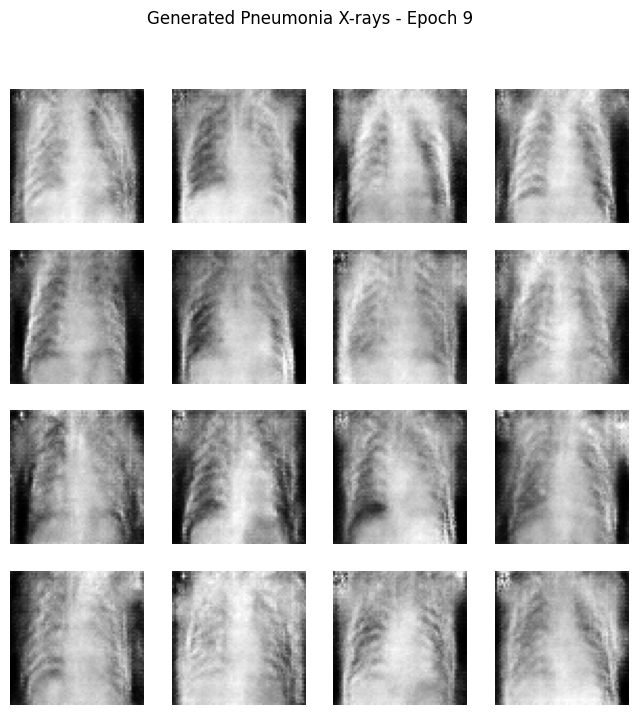

Epoch 10/20 Generator Loss: 0.8329 Discriminator Loss: 1.2552


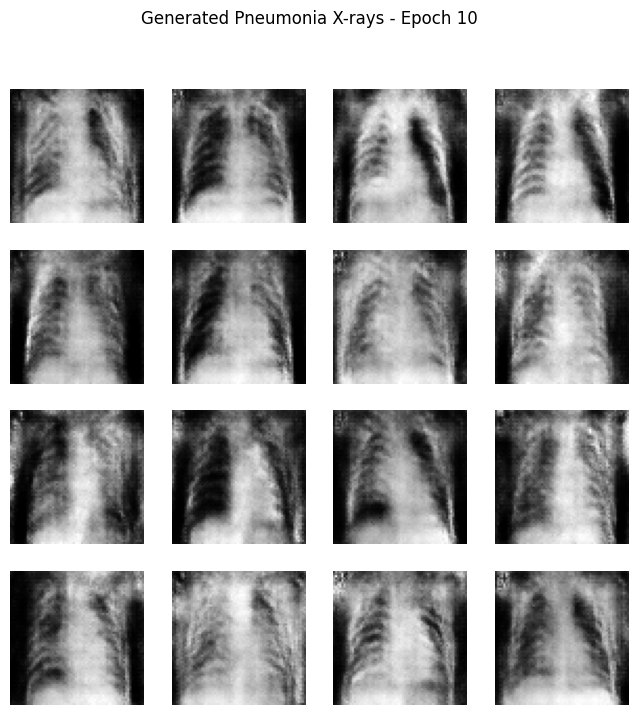

Epoch 11/20 Generator Loss: 0.8025 Discriminator Loss: 1.2484


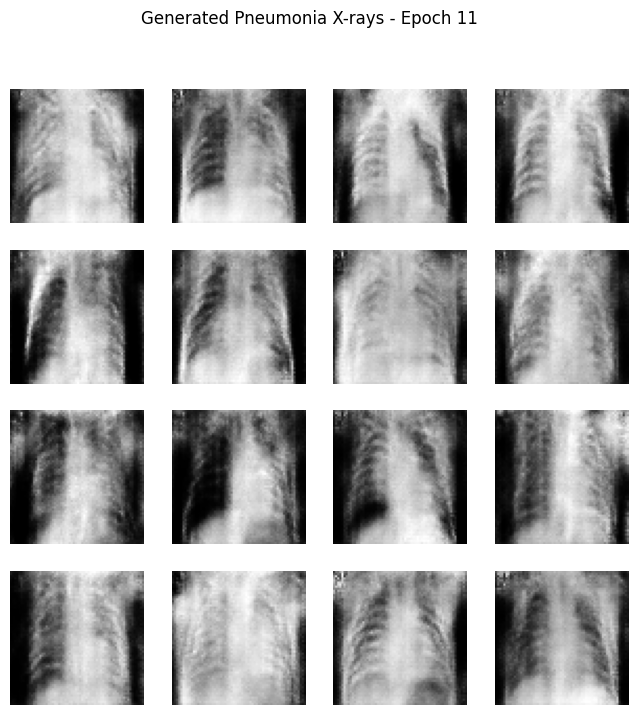

Epoch 12/20 Generator Loss: 0.8366 Discriminator Loss: 1.2582


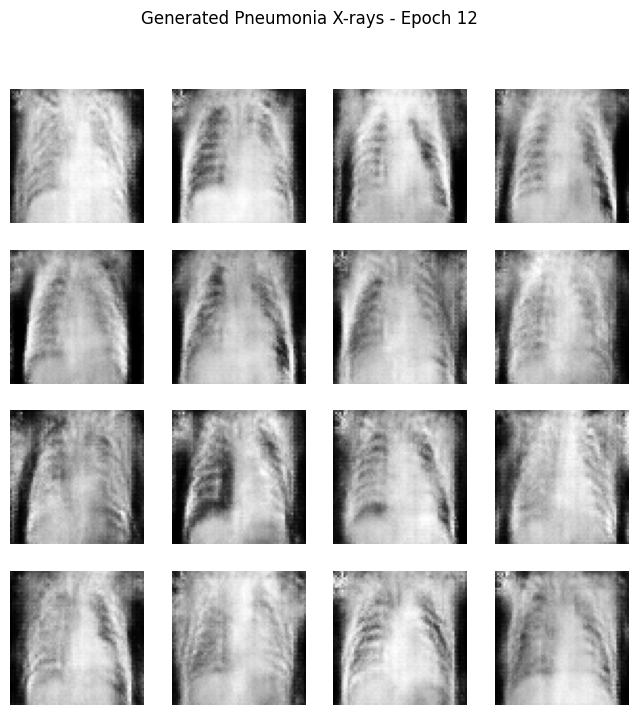

Epoch 13/20 Generator Loss: 0.8738 Discriminator Loss: 1.2136


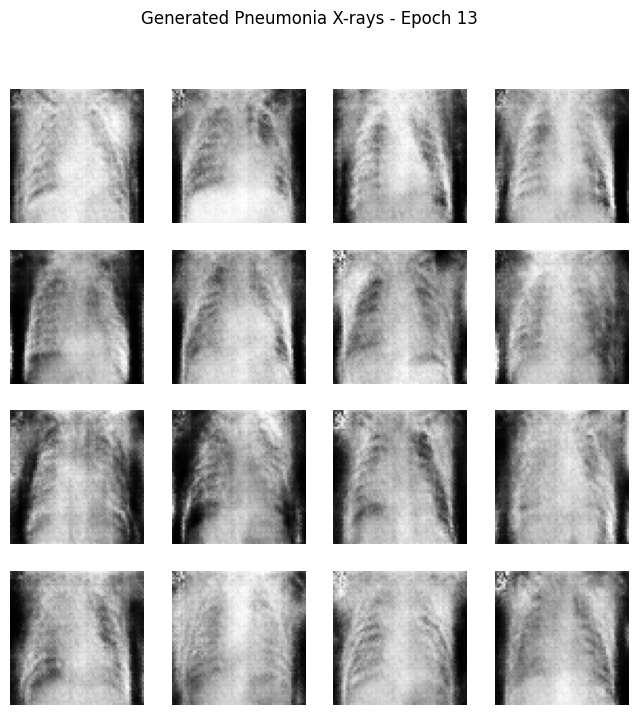

Epoch 14/20 Generator Loss: 0.8839 Discriminator Loss: 1.1971


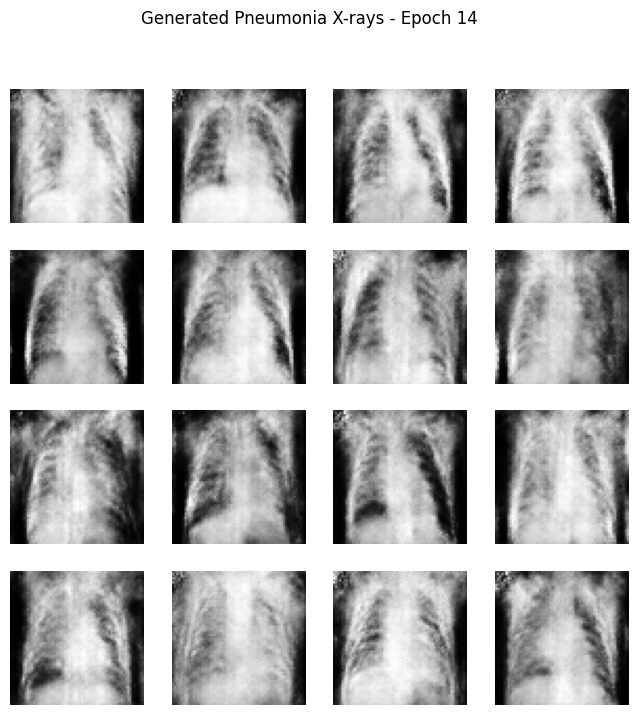

Epoch 15/20 Generator Loss: 0.8857 Discriminator Loss: 1.1753


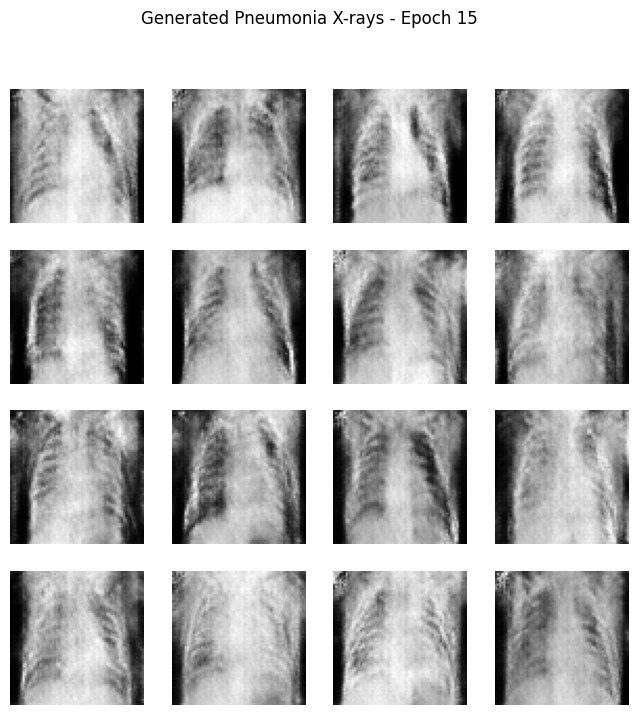

Epoch 16/20 Generator Loss: 0.8958 Discriminator Loss: 1.1622


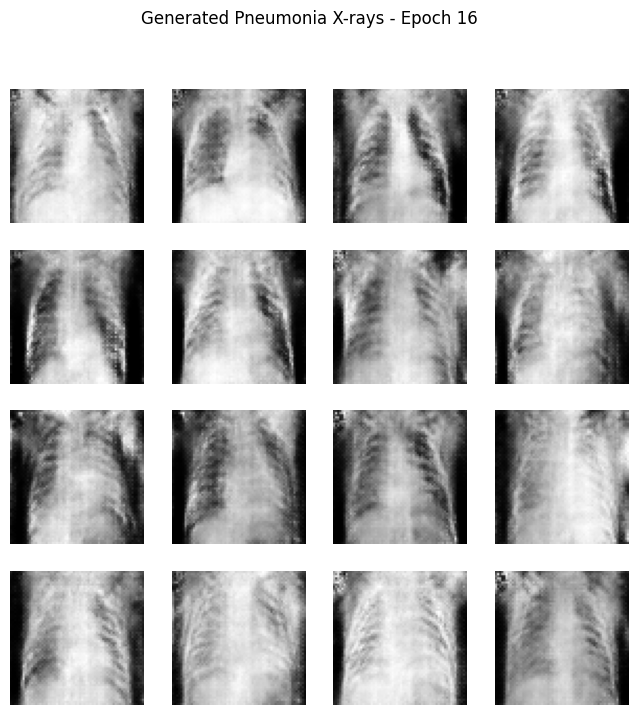

Epoch 17/20 Generator Loss: 0.9595 Discriminator Loss: 1.1245


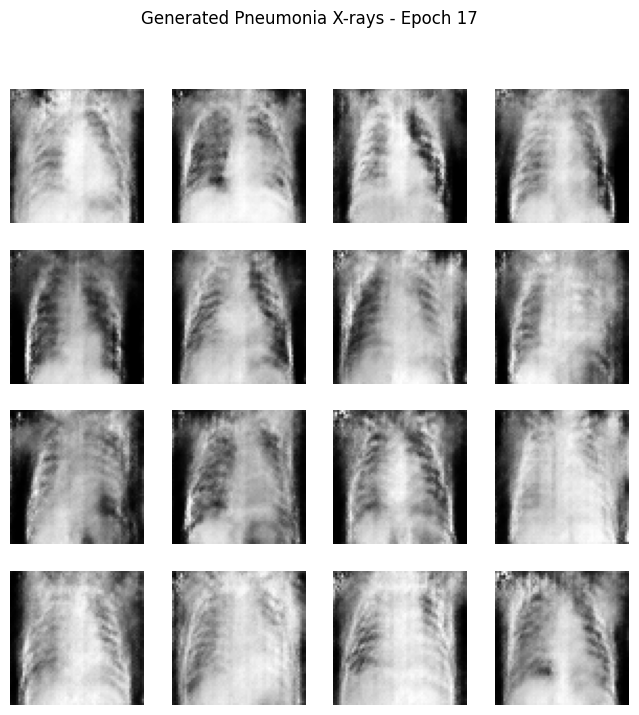

Epoch 18/20 Generator Loss: 0.9770 Discriminator Loss: 1.1181


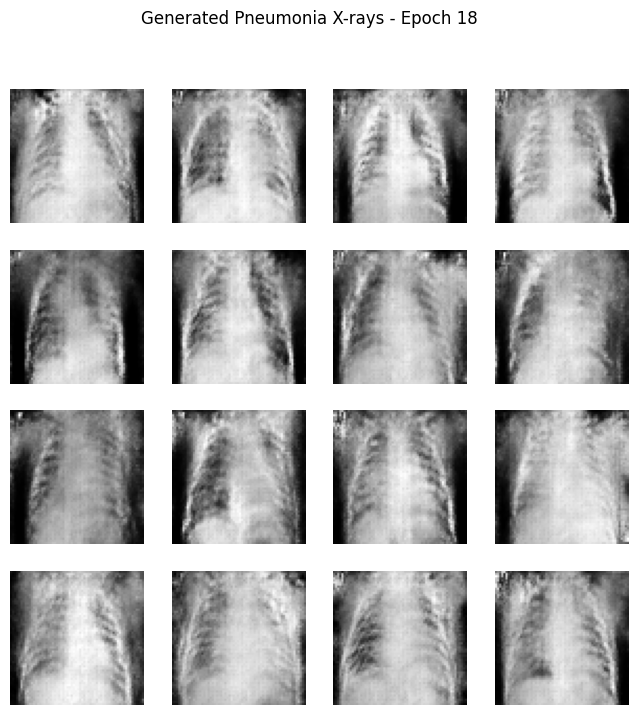

Epoch 19/20 Generator Loss: 0.9290 Discriminator Loss: 1.1494


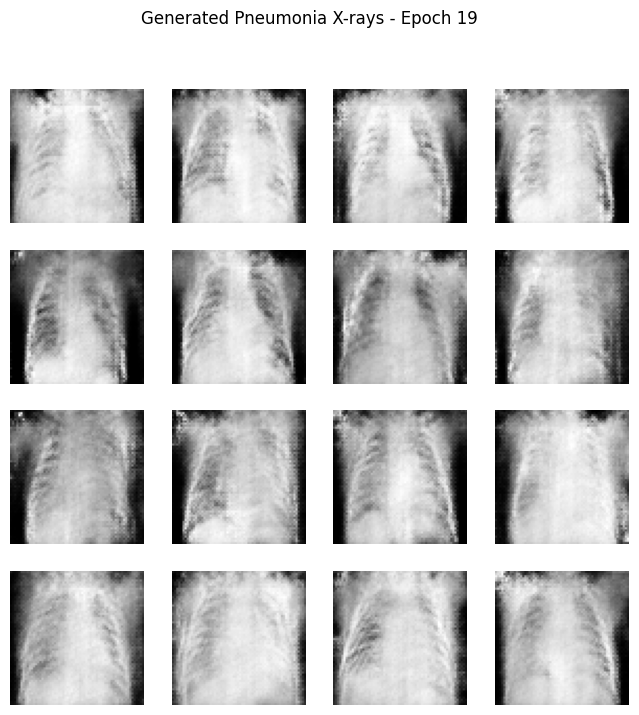

Epoch 20/20 Generator Loss: 0.9380 Discriminator Loss: 1.1409


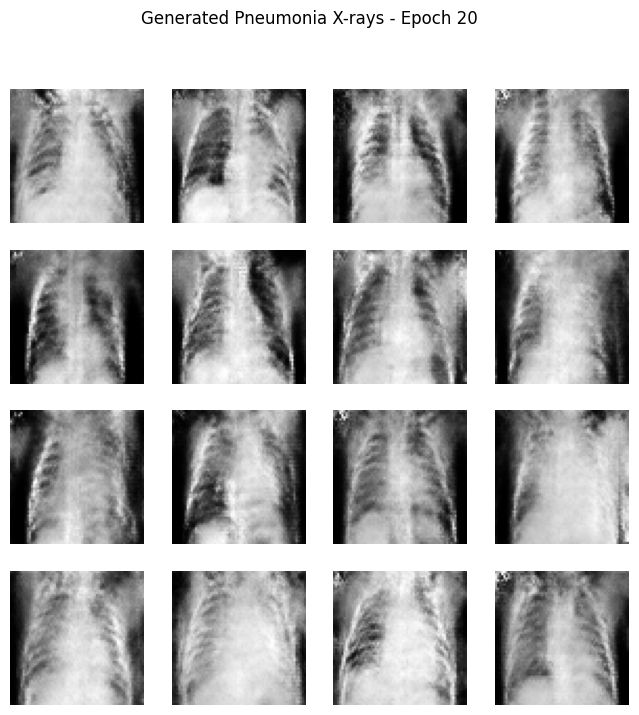

In [ ]:
EPOCHS = 20

for epoch in range(EPOCHS):

    gen_losses = []
    disc_losses = []

    for image_batch in dataset:

        g_loss, d_loss = train_step(image_batch)

        gen_losses.append(g_loss.numpy())
        disc_losses.append(d_loss.numpy())

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"Generator Loss: {np.mean(gen_losses):.4f} "
        f"Discriminator Loss: {np.mean(disc_losses):.4f}"
    )

    generate_and_show_images(
        generator,
        epoch + 1
    )

SAVING SYNTETIC X-RAY

In [ ]:
GENERATED_PATH = "/content/drive/MyDrive/PNEUMONIA"

os.makedirs(
    GENERATED_PATH,
    exist_ok=True
)

In [ ]:
NUM_IMAGES = 1000

for i in range(NUM_IMAGES):

    noise = tf.random.normal(
        [1, LATENT_DIM]
    )

    generated_image = generator(
        noise,
        training=False
    )

    # [-1,1] -> [0,255]
    generated_image = (
        (generated_image[0] + 1) * 127.5
    )

    generated_image = tf.cast(
        generated_image,
        tf.uint8
    )

    path = os.path.join(
        GENERATED_PATH,
        f"synthetic_pneumonia_{i+1}.png"
    )

    tf.keras.utils.save_img(
        path,
        generated_image
    )

print("Synthetic images saved!")

Synthetic images saved!


SYNTHETIC IMAGES CHECK

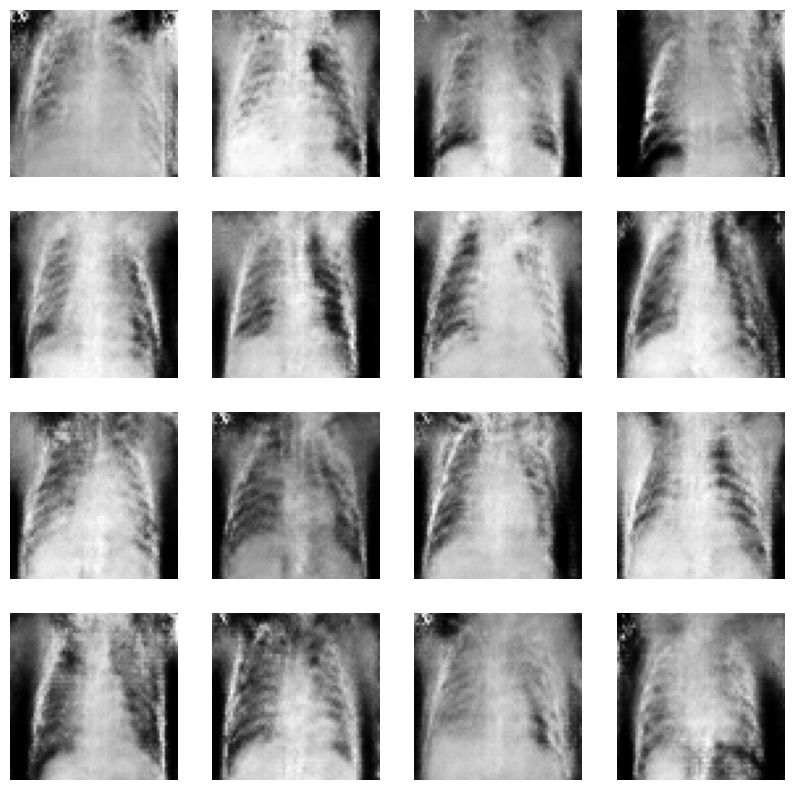

In [ ]:
files = [f for f in os.listdir(GENERATED_PATH) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

plt.figure(figsize=(10, 10))

for i in range(min(16, len(files))):

    img = tf.keras.utils.load_img(
        os.path.join(
            GENERATED_PATH,
            files[i]
        ),
        color_mode="grayscale"
    )

    plt.subplot(4, 4, i+1)
    plt.imshow(img, cmap="gray")
    plt.axis("off")

plt.show()

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True,
    validation_split=0.2
)

In [ ]:
import os
import shutil

original_train = "/content/extracted_images/chest_xray/train"

augmented_train = "/content/drive/MyDrive/augmented_train"

gan_pneumonia = "/content/drive/MyDrive/generated_pneumonia"

In [ ]:
train_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/augmented_train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="training"
)

val_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/augmented_train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="validation"
)

In [ ]:
os.makedirs(
    os.path.join(augmented_train, "NORMAL"),
    exist_ok=True
)

os.makedirs(
    os.path.join(augmented_train, "PNEUMONIA"),
    exist_ok=True
)

In [ ]:
def copy_images(source, destination):

    count = 0

    for file in os.listdir(source):

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            src = os.path.join(source, file)
            dst = os.path.join(destination, file)

            shutil.copy2(src, dst)

            count += 1

    return count

In [ ]:
normal_count = copy_images(
    os.path.join(original_train, "NORMAL"),
    os.path.join(augmented_train, "NORMAL")
)

pneumonia_count = copy_images(
    os.path.join(original_train, "PNEUMONIA"),
    os.path.join(augmented_train, "PNEUMONIA")
)

print("Original NORMAL:", normal_count)
print("Original PNEUMONIA:", pneumonia_count)

Original NORMAL: 1349
Original PNEUMONIA: 3883


In [ ]:
augmented_train = "/content/drive/MyDrive/augmented_train"

In [ ]:
import os

print(os.path.exists(augmented_train))

True


In [ ]:
gan_pneumonia = "/content/drive/MyDrive/generated_pneumonia"

In [ ]:
print(os.path.exists(gan_pneumonia))

automatically folder from colab

In [ ]:
import os

augmented_train = "/content/drive/MyDrive/augmented_train"
gan_pneumonia = "/content/drive/MyDrive/generated_pneumonia"

os.makedirs(augmented_train, exist_ok=True)
os.makedirs(gan_pneumonia, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [ ]:
print(os.listdir("/content/drive/MyDrive"))

['chhest X-ray with GAN.ipynb', 'How to get started with Drive.pdf', 'BIODATA 2.doc', 'IMG_20180805_222139.jpg', 'IMG-20190730-WA0002.jpg', ' MyDoc 12:00:22.pdf', 'Classroom', 'IMG20210221150539.jpg', 'Nasima Khatun (1).pdf', 'Professional certificate course brochure .pdf', 'Colab Notebooks', 'NOC25062617509345894538.pdf', 'IMG_20250715_204528.jpg', 'Copy of 1_Churn_Modelling.gsheet', 'Nisarg sir AI', 'Copy of 21-jul-25-AIE-WDM11-BAN.gsheet', 'Working with RDDs in PySpark.ipynb', 'Copy_of_sql_connection_(1).ipynb', 'imgtopdf_2508251508025.pdf', 'colab dataset', 'Copy of 3_ANN_Implementation_for_classification.ipynb', 'Internship_certificate.pdf', 'IMG.pdf', 'certificate(7).pdf', 'Copy of MobileNetSSD_deploy.prototxt', 'Copy of yolo_v8_implementation.ipynb', 'NLP_generic_concepts.ipynb', 'NKTK_Hands_On.ipynb', 'spam.tsv', 'Naive_Bayes_Algorithm.ipynb', 'yolo.pdf', 'Text processing techniques.ipynb', 'NLP_New.ipynb', 'IMG_20260105_210925.jpg', 'certificate(4).pdf', 'Sample Interview Ques

In [ ]:
GENERATED_PATH = "/content/drive/MyDrive/generated_pneumonia"

augmented dataset making

In [ ]:
AUGMENTED_PATH = "/content/drive/MyDrive/augmented_train"

os.makedirs(
    os.path.join(AUGMENTED_PATH, "NORMAL"),
    exist_ok=True
)

os.makedirs(
    os.path.join(AUGMENTED_PATH, "PNEUMONIA"),
    exist_ok=True
)

  ORIGINAL IMAGES COPY

In [ ]:
def copy_images(source, destination):

    count = 0

    for file in os.listdir(source):

        if file.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            shutil.copy2(
                os.path.join(source, file),
                os.path.join(destination, file)
            )

            count += 1

    return count

In [ ]:
normal_count = copy_images(
    os.path.join(original_train, "NORMAL"),
    os.path.join(AUGMENTED_PATH, "NORMAL")
)

pneumonia_count = copy_images(
    os.path.join(original_train, "PNEUMONIA"),
    os.path.join(AUGMENTED_PATH, "PNEUMONIA")
)

print("Original NORMAL:", normal_count)
print("Original PNEUMONIA:", pneumonia_count)

Original NORMAL: 1349
Original PNEUMONIA: 3883


GAN IMAGES COPY

In [ ]:
synthetic_count = copy_images(
    GENERATED_PATH,
    os.path.join(
        AUGMENTED_PATH,
        "PNEUMONIA"
    )
)

print(
    "Synthetic Pneumonia:",
    synthetic_count
)

Synthetic Pneumonia: 0


In [ ]:
print(
    "Final NORMAL:",
    len(os.listdir(
        os.path.join(
            AUGMENTED_PATH,
            "NORMAL"
        )
    ))
)

print(
    "Final PNEUMONIA:",
    len(os.listdir(
        os.path.join(
            AUGMENTED_PATH,
            "PNEUMONIA"
        )
    ))
)

Final NORMAL: 1349
Final PNEUMONIA: 3883


GAN generated pneumonia images copy

In [ ]:
synthetic_count = copy_images(
    gan_pneumonia,
    os.path.join(augmented_train, "PNEUMONIA")
)

print("Synthetic Pneumonia:", synthetic_count)

Synthetic Pneumonia: 0


In [ ]:
normal_total = len(os.listdir(
    os.path.join(augmented_train, "NORMAL")
))

pneumonia_total = len(os.listdir(
    os.path.join(augmented_train, "PNEUMONIA")
))

print("NORMAL =", normal_total)
print("PNEUMONIA =", pneumonia_total)

NORMAL = 1349
PNEUMONIA = 3883


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    horizontal_flip=True,
    validation_split=0.2
)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/augmented_train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="training"
)

val_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/augmented_train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="validation"
)

Found 4187 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    shear_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/augmented_train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    "/content/drive/MyDrive/augmented_train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=42
)

Found 4187 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.


In [ ]:
print(train_generator.class_indices)
print("Training:", train_generator.samples)
print("Validation:", val_generator.samples)

{'NORMAL': 0, 'PNEUMONIA': 1}
Training: 4187
Validation: 1045


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
TRAIN_DIR = "/content/drive/MyDrive/augmented_train"
TEST_DIR  = "/content/extracted_images/chest_xray/test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.15,
    shear_range=0.1,
    horizontal_flip=True,
    validation_split=0.2
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 4187 images belonging to 2 classes.
Found 1045 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [ ]:
print(train_generator.class_indices)

{'NORMAL': 0, 'PNEUMONIA': 1}


COMMON FUNCTION

In [ ]:
def build_transfer_model(base_model):

    base_model.trainable = False

    x = base_model.output

    x = GlobalAveragePooling2D()(x)

    x = Dense(256, activation="relu")(x)

    x = Dropout(0.5)(x)

    output = Dense(
        1,
        activation="sigmoid"
    )(x)

    model = Model(
        inputs=base_model.input,
        outputs=output
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.0001
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

    return model

VGG16 MODEL

In [ ]:
vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg_model = build_transfer_model(vgg_base)

vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
vgg_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        "/content/drive/MyDrive/vgg16_best.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [ ]:
history_vgg = vgg_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=vgg_callbacks
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 184s 1s/step - accuracy: 0.7423 - loss: 0.5478 - precision: 0.7546 - recall: 0.9672 - val_accuracy: 0.7426 - val_loss: 0.4584 - val_precision: 0.7426 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.7929 - loss: 0.4416 - precision: 0.7915 - recall: 0.9788 - val_accuracy: 0.8211 - val_loss: 0.3869 - val_precision: 0.8084 - val_recall: 0.9948 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 170s 1s/step - accuracy: 0.8221 - loss: 0.3768 - precision: 0.8255 - recall: 0.9640 - val_accuracy: 0.8545 - val_loss: 0.3402 - val_precision: 0.8545 - val_recall: 0.9691 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.8593 - loss: 0.3295 - precision: 0.8696 - recall: 0.9533 - val_accuracy: 0.8718 - val_loss: 0.3021 - val_precision: 0.8776 - val_recall: 0.9613 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 135s

RESNET50 MODEL

In [ ]:
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_model = build_transfer_model(resnet_base)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resnet_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        "/content/drive/MyDrive/resnet50_best.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [ ]:
history_resnet = resnet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=resnet_callbacks
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 153s 1s/step - accuracy: 0.7122 - loss: 0.6163 - precision: 0.7449 - recall: 0.9311 - val_accuracy: 0.7426 - val_loss: 0.5561 - val_precision: 0.7426 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 126s 961ms/step - accuracy: 0.7375 - loss: 0.5703 - precision: 0.7455 - recall: 0.9813 - val_accuracy: 0.7426 - val_loss: 0.5339 - val_precision: 0.7426 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 126s 961ms/step - accuracy: 0.7437 - loss: 0.5375 - precision: 0.7444 - recall: 0.9971 - val_accuracy: 0.7435 - val_loss: 0.5351 - val_precision: 0.7456 - val_recall: 0.9936 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 125s 956ms/step - accuracy: 0.7425 - loss: 0.5137 - precision: 0.7455 - recall: 0.9916 - val_accuracy: 0.7579 - val_loss: 0.5354 - val_precision: 0.7738 - val_recall: 0.9523 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━

DENSENET 121

In [ ]:
densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

densenet_model = build_transfer_model(
    densenet_base
)

densenet_model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,300,161 (27.85 MB)

 Trainable params: 262,657 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
densenet_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        "/content/drive/MyDrive/densenet121_best.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [ ]:
history_densenet = densenet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=densenet_callbacks
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.8128 - loss: 0.3978 - precision: 0.8427 - recall: 0.9192 - val_accuracy: 0.9033 - val_loss: 0.2404 - val_precision: 0.9278 - val_recall: 0.9433 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.8983 - loss: 0.2528 - precision: 0.9177 - recall: 0.9479 - val_accuracy: 0.9062 - val_loss: 0.2181 - val_precision: 0.9437 - val_recall: 0.9291 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 130s 997ms/step - accuracy: 0.9164 - loss: 0.2133 - precision: 0.9336 - recall: 0.9553 - val_accuracy: 0.9378 - val_loss: 0.1789 - val_precision: 0.9564 - val_recall: 0.9601 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 140s 983ms/step - accuracy: 0.9238 - loss: 0.1872 - precision: 0.9437 - recall: 0.9543 - val_accuracy: 0.9388 - val_loss: 0.1626 - val_precision: 0.9506 - val_recall: 0.9678 - learning_rate: 1.0000e-04
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━

In [ ]:
loss, accuracy, precision, recall = vgg_model.evaluate(test_generator)

print("VGG16:")
print("Loss:", loss)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)


20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 747ms/step - accuracy: 0.8718 - loss: 0.3303 - precision: 0.8475 - recall: 0.9692
VGG16:
Loss: 0.3302847445011139
Accuracy: 0.8717948794364929
Precision: 0.847533643245697
Recall: 0.9692307710647583


In [ ]:
loss, accuracy, precision, recall = resnet_model.evaluate(test_generator)

print("RESNET50:")
print("Loss:", loss)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 468ms/step - accuracy: 0.6458 - loss: 0.5724 - precision: 0.6425 - recall: 0.9769
RESNET50:
Loss: 0.5723518133163452
Accuracy: 0.6458333134651184
Precision: 0.6424958109855652
Recall: 0.9769230484962463


In [ ]:
loss, accuracy, precision, recall = densenet_model.evaluate(test_generator)

print("DENSENET121:")
print("Loss:", loss)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 879ms/step - accuracy: 0.8670 - loss: 0.3296 - precision: 0.8389 - recall: 0.9744
DENSENET121:
Loss: 0.3296401798725128
Accuracy: 0.8669871687889099
Precision: 0.8388521075248718
Recall: 0.9743589758872986


TEST EVALUATION

In [ ]:
def evaluate_model(model, generator, model_name):

    generator.reset()

    probabilities = model.predict(
        generator,
        verbose=1
    ).ravel()

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    true_labels = generator.classes

    accuracy = accuracy_score(
        true_labels,
        predictions
    )

    precision = precision_score(
        true_labels,
        predictions
    )

    recall = recall_score(
        true_labels,
        predictions
    )

    f1 = f1_score(
        true_labels,
        predictions
    )

    fpr, tpr, _ = roc_curve(
        true_labels,
        probabilities
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    print("\n", "="*50)
    print(model_name)
    print("="*50)

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)
    print("ROC-AUC  :", roc_auc)

    print("\nClassification Report\n")

    print(
        classification_report(
            true_labels,
            predictions,
            target_names=[
                "NORMAL",
                "PNEUMONIA"
            ]
        )
    )

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": roc_auc,
        "true": true_labels,
        "pred": predictions,
        "probabilities": probabilities,
        "fpr": fpr,
        "tpr": tpr
    }

In [ ]:
vgg_result = evaluate_model(
    vgg_model,
    test_generator,
    "VGG16"
)

resnet_result = evaluate_model(
    resnet_model,
    test_generator,
    "ResNet50"
)

densenet_result = evaluate_model(
    densenet_model,
    test_generator,
    "DenseNet121"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 268ms/step

VGG16
Accuracy : 0.8717948717948718
Precision: 0.8475336322869955
Recall   : 0.9692307692307692
F1 Score : 0.9043062200956937
ROC-AUC  : 0.9400394477317555

Classification Report

              precision    recall  f1-score   support

      NORMAL       0.93      0.71      0.81       234
   PNEUMONIA       0.85      0.97      0.90       390

    accuracy                           0.87       624
   macro avg       0.89      0.84      0.86       624
weighted avg       0.88      0.87      0.87       624

20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 381ms/step

ResNet50
Accuracy : 0.6458333333333334
Precision: 0.642495784148398
Recall   : 0.9769230769230769
F1 Score : 0.775178026449644
ROC-AUC  : 0.844564979180364

Classification Report

              precision    recall  f1-score   support

      NORMAL       0.71      0.09      0.17       234
   PNEUMONIA       0.64      0.98      0.78       390

    accuracy                           0.65       624
   macro a

COMPARISON TABLE

In [ ]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": vgg_result["model"],
        "Accuracy": vgg_result["accuracy"],
        "Precision": vgg_result["precision"],
        "Recall": vgg_result["recall"],
        "F1": vgg_result["f1"],
        "AUC": vgg_result["auc"]
    },

    {
        "Model": resnet_result["model"],
        "Accuracy": resnet_result["accuracy"],
        "Precision": resnet_result["precision"],
        "Recall": resnet_result["recall"],
        "F1": resnet_result["f1"],
        "AUC": resnet_result["auc"]
    },

    {
        "Model": densenet_result["model"],
        "Accuracy": densenet_result["accuracy"],
        "Precision": densenet_result["precision"],
        "Recall": densenet_result["recall"],
        "F1": densenet_result["f1"],
        "AUC": densenet_result["auc"]
    }
])

results

,Model,Accuracy,Precision,Recall,F1,AUC
0,VGG16,0.871795,0.847534,0.969231,0.904306,0.940039
1,ResNet50,0.645833,0.642496,0.976923,0.775178,0.844565
2,DenseNet121,0.866987,0.838852,0.974359,0.901542,0.954460


CONFUSION MATRIX

In [ ]:
def plot_confusion_matrix(result):

    cm = confusion_matrix(
        result["true"],
        result["pred"]
    )

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "NORMAL",
            "PNEUMONIA"
        ],
        yticklabels=[
            "NORMAL",
            "PNEUMONIA"
        ]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(
        f"Confusion Matrix - {result['model']}"
    )

    plt.show()

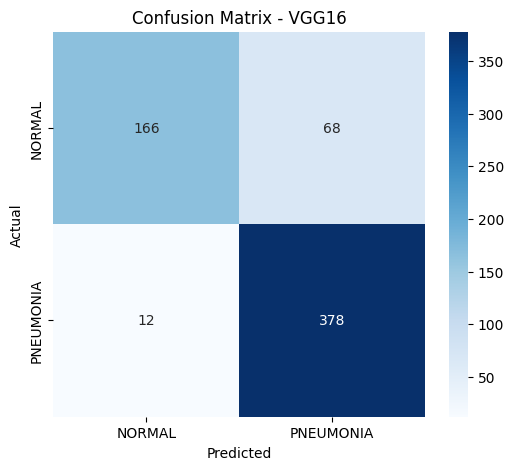

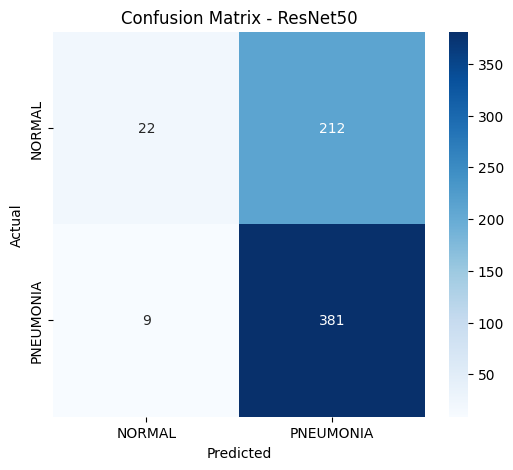

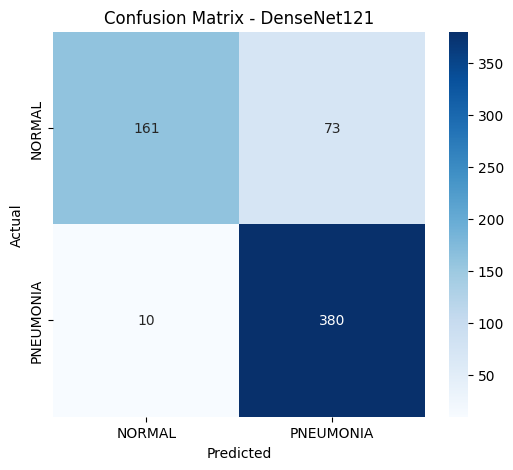

In [ ]:
plot_confusion_matrix(vgg_result)
plot_confusion_matrix(resnet_result)
plot_confusion_matrix(densenet_result)

ROC-AUC COMPARISON

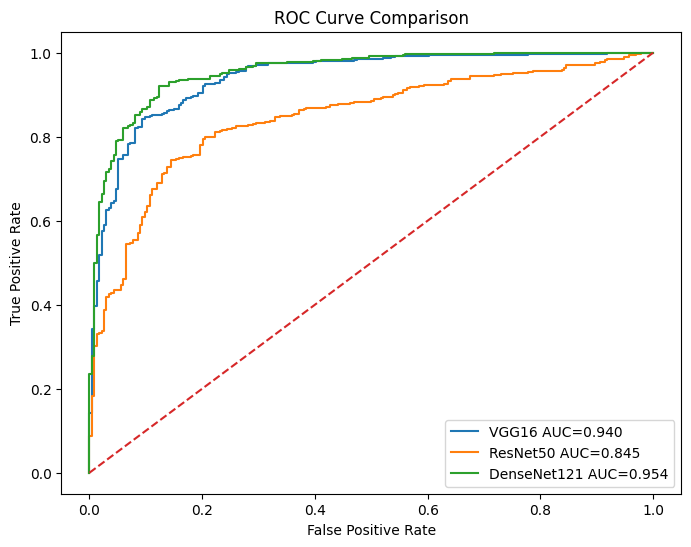

In [ ]:
plt.figure(figsize=(8,6))

plt.plot(
    vgg_result["fpr"],
    vgg_result["tpr"],
    label=f"VGG16 AUC={vgg_result['auc']:.3f}"
)

plt.plot(
    resnet_result["fpr"],
    resnet_result["tpr"],
    label=f"ResNet50 AUC={resnet_result['auc']:.3f}"
)

plt.plot(
    densenet_result["fpr"],
    densenet_result["tpr"],
    label=f"DenseNet121 AUC={densenet_result['auc']:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

TRAINING - VALIDATION ACCURACY

In [ ]:
def plot_history(history, model_name):

    plt.figure(figsize=(8,5))

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"{model_name} Accuracy"
    )

    plt.legend()
    plt.show()

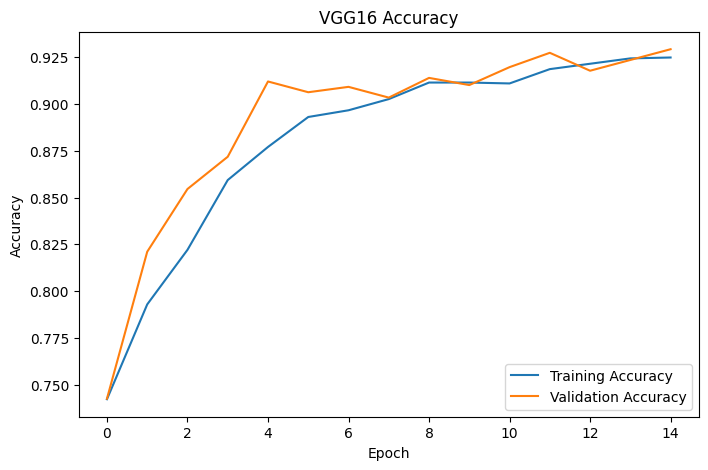

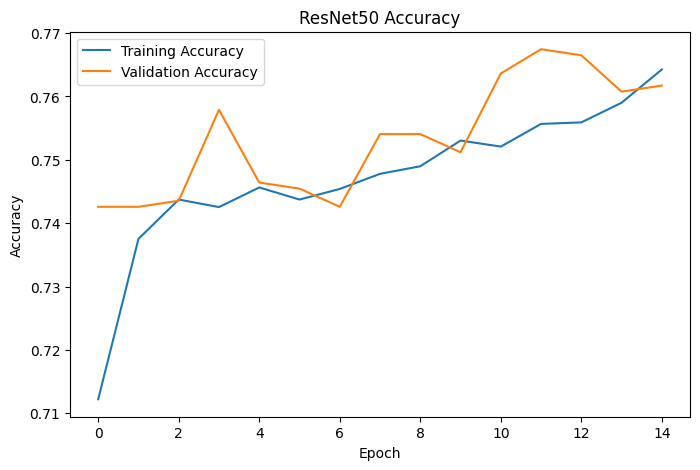

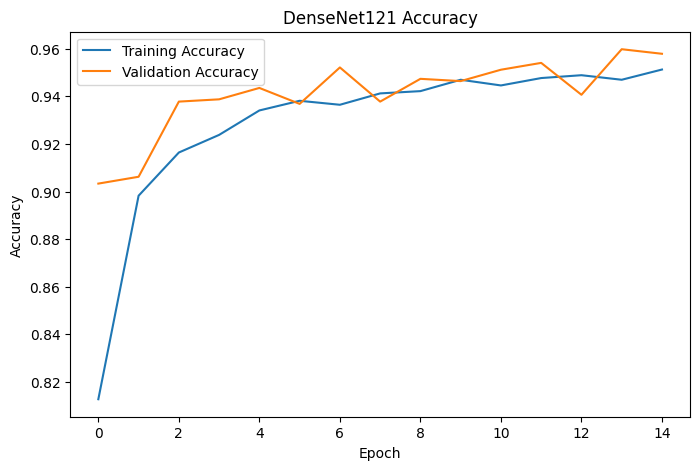

In [ ]:
plot_history(history_vgg, "VGG16")
plot_history(history_resnet, "ResNet50")
plot_history(history_densenet, "DenseNet121")

In [ ]:
                 CHEST X-RAY DATASET
                         │
                         ▼
                  Preprocessing
                         │
             ┌───────────┴───────────┐
             │                       │
             ▼                       ▼
          Original                 DCGAN
          X-rays              Synthetic X-rays
             │                       │
             └───────────┬───────────┘
                         ▼
                 Augmented Train Set
                         │
        ┌────────────────┼────────────────┐
        ▼                ▼                ▼
      VGG16           ResNet50        DenseNet121
        │                │                │
        └────────────────┼────────────────┘
                         ▼
                  Model Comparison
                         │
          Accuracy / Precision / Recall
                F1 / ROC-AUC
                         │
                         ▼
                 Best Model Selection
                         │
                         ▼
                     Grad-CAM
                         │
                         ▼
               Pneumonia Prediction
                         │
                         ▼
                  FastAPI Backend
                         │
              ┌──────────┴──────────┐
              ▼                     ▼
           /predict                /chat
              │                     │
              ▼                     ▼
       X-ray prediction       Claude explanation

In [ ]:
def plot_accuracy(history, model_name):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"{model_name} Training vs Validation Accuracy"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

In [ ]:
def plot_loss(history, model_name):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"{model_name} Training vs Validation Loss"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

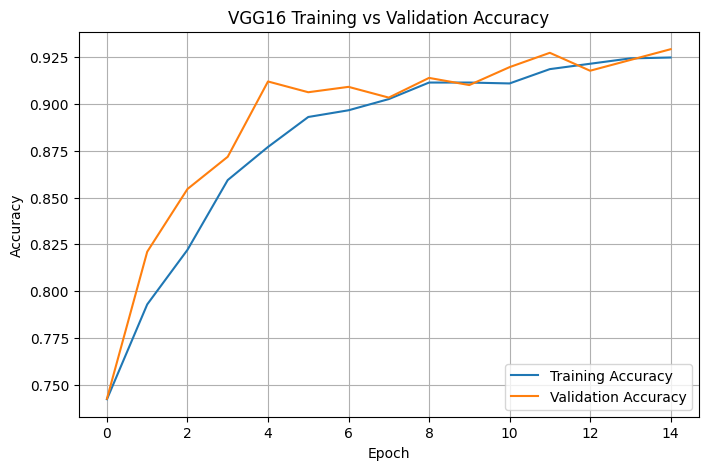

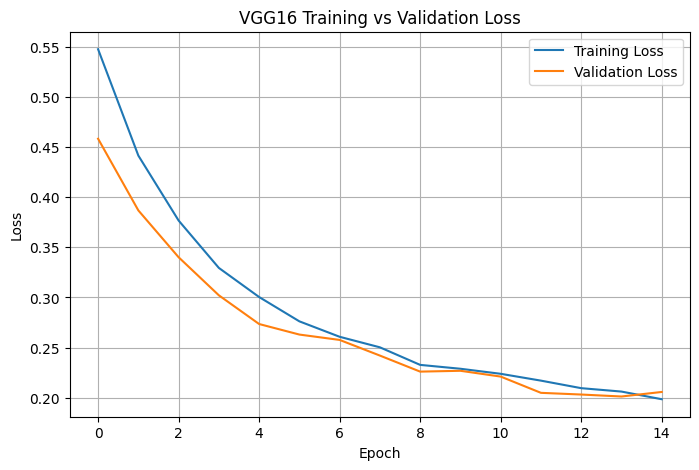

In [ ]:
plot_accuracy(history_vgg, "VGG16")
plot_loss(history_vgg, "VGG16")

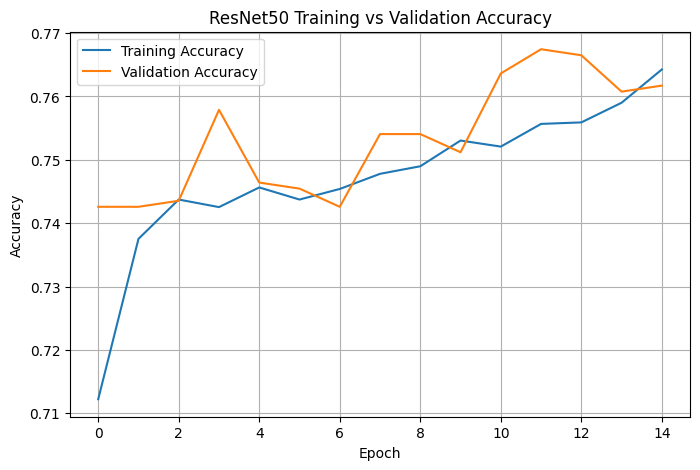

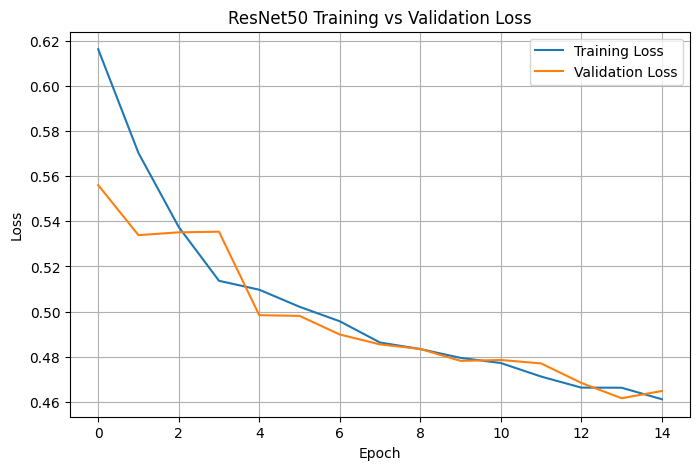

In [ ]:
plot_accuracy(history_resnet, "ResNet50")
plot_loss(history_resnet, "ResNet50")

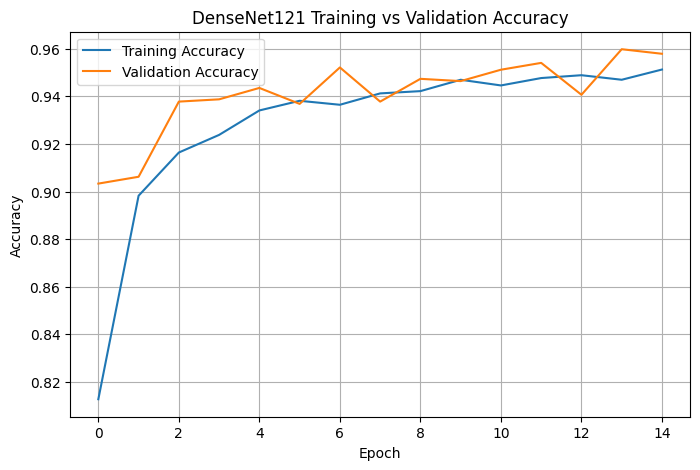

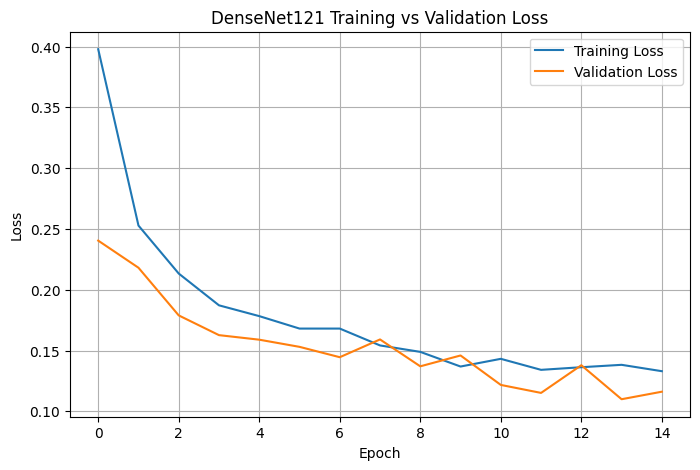

In [ ]:
plot_accuracy(history_densenet, "DenseNet121")
plot_loss(history_densenet, "DenseNet121")

In [ ]:
from sklearn.metrics import confusion_matrix

def sensitivity_specificity(model, generator, model_name):

    generator.reset()

    # Prediction probability
    probabilities = model.predict(
        generator,
        verbose=1
    ).ravel()

    # Convert probability to class
    predictions = (
        probabilities >= 0.5
    ).astype(int)

    true_labels = generator.classes

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        true_labels,
        predictions
    ).ravel()

    # Sensitivity = TP / (TP + FN)
    sensitivity = tp / (tp + fn)

    # Specificity = TN / (TN + FP)
    specificity = tn / (tn + fp)

    print("\n" + "="*50)
    print(model_name)
    print("="*50)

    print("True Positive  (TP):", tp)
    print("True Negative  (TN):", tn)
    print("False Positive (FP):", fp)
    print("False Negative (FN):", fn)

    print(
        f"\nSensitivity (Recall): {sensitivity:.4f}"
    )

    print(
        f"Specificity: {specificity:.4f}"
    )

    print(
        f"\nSensitivity: {sensitivity*100:.2f}%"
    )

    print(
        f"Specificity: {specificity*100:.2f}%"
    )

    return sensitivity, specificity

In [ ]:
vgg_sens, vgg_spec = sensitivity_specificity(
    vgg_model,
    test_generator,
    "VGG16"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 253ms/step

VGG16
True Positive  (TP): 378
True Negative  (TN): 166
False Positive (FP): 68
False Negative (FN): 12

Sensitivity (Recall): 0.9692
Specificity: 0.7094

Sensitivity: 96.92%
Specificity: 70.94%


In [ ]:
resnet_sens, resnet_spec = sensitivity_specificity(
    resnet_model,
    test_generator,
    "ResNet50"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 225ms/step

ResNet50
True Positive  (TP): 381
True Negative  (TN): 22
False Positive (FP): 212
False Negative (FN): 9

Sensitivity (Recall): 0.9769
Specificity: 0.0940

Sensitivity: 97.69%
Specificity: 9.40%


In [ ]:
densenet_sens, densenet_spec = sensitivity_specificity(
    densenet_model,
    test_generator,
    "DenseNet121"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 225ms/step

DenseNet121
True Positive  (TP): 380
True Negative  (TN): 161
False Positive (FP): 73
False Negative (FN): 10

Sensitivity (Recall): 0.9744
Specificity: 0.6880

Sensitivity: 97.44%
Specificity: 68.80%


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "VGG16",
        "ResNet50",
        "DenseNet121"
    ],

    "Sensitivity (%)": [
        vgg_sens * 100,
        resnet_sens * 100,
        densenet_sens * 100
    ],

    "Specificity (%)": [
        vgg_spec * 100,
        resnet_spec * 100,
        densenet_spec * 100
    ]
})

comparison

,Model,Sensitivity (%),Specificity (%)
0,VGG16,96.923077,70.940171
1,ResNet50,97.692308,9.401709
2,DenseNet121,97.435897,68.803419


SELECTED BEST MODEL

In [ ]:
model_dict = {
    "VGG16": vgg_model,
    "ResNet50": resnet_model,
    "DenseNet121": densenet_model
}

# Determine the best model based on accuracy from the results DataFrame
best_model_name = results.loc[results['Accuracy'].idxmax()]['Model']
best_model = model_dict[best_model_name]

print(
    "Selected model:",
    best_model_name
)


Selected model: VGG16


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.models import Model

In [ ]:
last_conv_layer_name = "block5_conv3"

print(vgg_model.get_layer(last_conv_layer_name))

<Conv2D name=block5_conv3, built=True>


In [ ]:
def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name
):

    # Model that outputs convolutional features
    grad_model = Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(
                last_conv_layer_name
            ).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        # Binary classification
        prediction = predictions[:, 0]

    # Gradient of prediction
    grads = tape.gradient(
        prediction,
        conv_outputs
    )

    # Average gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]

    pooled_grads = pooled_grads[0]

    # Weight feature maps
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(
        heatmap
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:

        heatmap /= max_value

    return heatmap.numpy()

In [ ]:
def load_xray_image(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(
        img
    )

    img_array = img_array / 255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    return img, img_array

In [ ]:
def display_gradcam(
    image_path,
    model,
    last_conv_layer_name
):

    # Load image
    original_img, img_array = load_xray_image(
        image_path
    )

    # Prediction
    prediction = model.predict(
        img_array,
        verbose=0
    )[0][0]

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array,
        model,
        last_conv_layer_name
    )

    # Convert heatmap to RGB
    heatmap = np.uint8(
        255 * heatmap
    )

    jet = plt.colormaps["jet"]

    jet_colors = jet(
        np.arange(256)
    )[:, :3]

    jet_heatmap = jet_colors[
        heatmap
    ]

    jet_heatmap = tf.keras.utils.array_to_img(
        jet_heatmap
    )

    jet_heatmap = jet_heatmap.resize(
        (224, 224)
    )

    jet_heatmap = tf.keras.utils.img_to_array(
        jet_heatmap
    )

    # Original image
    original_array = np.array(
        original_img
    )

    # Overlay
    overlay = (
        jet_heatmap * 0.4
        + original_array
    )

    overlay = np.uint8(
        np.clip(
            overlay,
            0,
            255
        )
    )

    # Prediction label
    if prediction >= 0.5:

        label = "PNEUMONIA"

        confidence = prediction * 100

    else:

        label = "NORMAL"

        confidence = (1 - prediction) * 100

    # Plot
    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        original_img,
        cmap="gray"
    )

    plt.title(
        "Original X-ray"
    )

    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        heatmap,
        cmap="jet"
    )

    plt.title(
        "Grad-CAM Heatmap"
    )

    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)

    plt.imshow(
        overlay
    )

    plt.title(
        f"{label}\nConfidence: {confidence:.2f}%"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

In [ ]:
test_path = "/content/extracted_images/chest_xray/test"

normal_path = os.path.join(
    test_path,
    "NORMAL"
)

pneumonia_path = os.path.join(
    test_path,
    "PNEUMONIA"
)

In [ ]:
normal_images = [
    os.path.join(
        normal_path,
        f
    )
    for f in os.listdir(normal_path)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

pneumonia_images = [
    os.path.join(
        pneumonia_path,
        f
    )
    for f in os.listdir(pneumonia_path)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

In [ ]:
selected_images = (
    normal_images[:5]
    + pneumonia_images[:5]
)

print(
    "Total images:",
    len(selected_images)
)

Total images: 10



Image 1/10
/content/extracted_images/chest_xray/test/NORMAL/NORMAL2-IM-0131-0001.jpeg


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_27']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


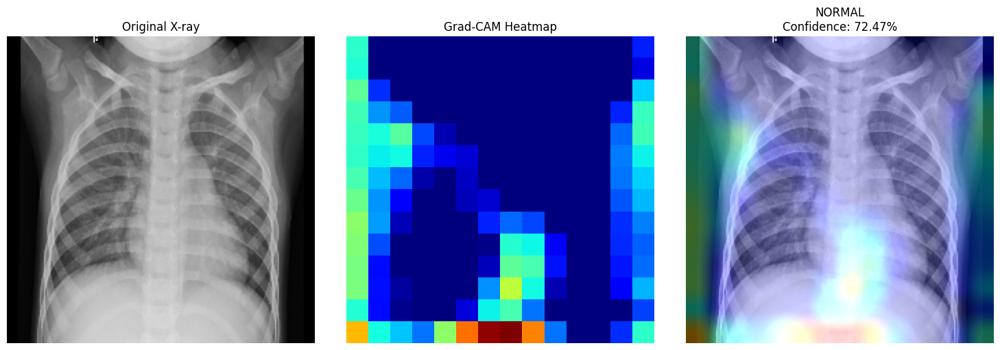


Image 2/10
/content/extracted_images/chest_xray/test/NORMAL/NORMAL2-IM-0328-0001.jpeg


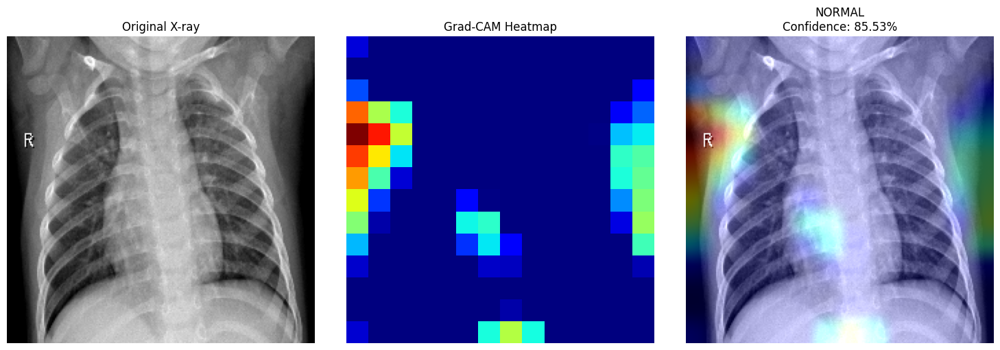


Image 3/10
/content/extracted_images/chest_xray/test/NORMAL/NORMAL2-IM-0374-0001.jpeg


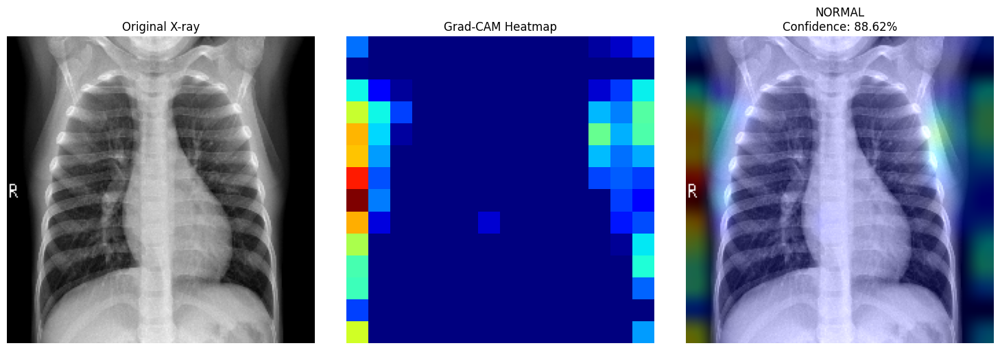


Image 4/10
/content/extracted_images/chest_xray/test/NORMAL/NORMAL2-IM-0123-0001.jpeg


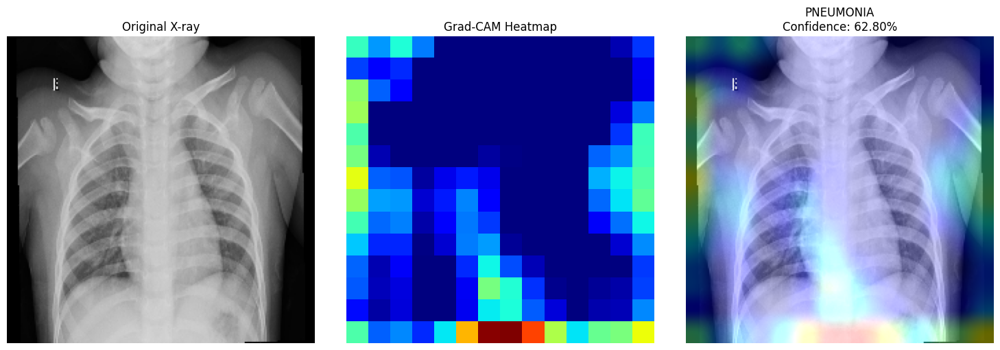


Image 5/10
/content/extracted_images/chest_xray/test/NORMAL/IM-0043-0001.jpeg


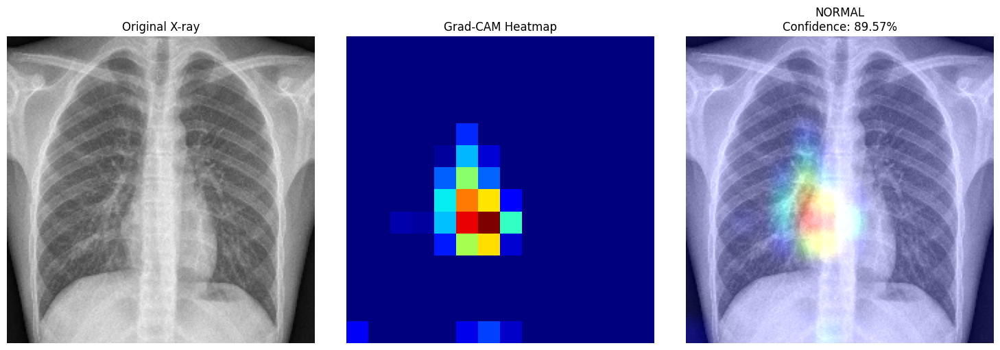


Image 6/10
/content/extracted_images/chest_xray/test/PNEUMONIA/person48_virus_100.jpeg


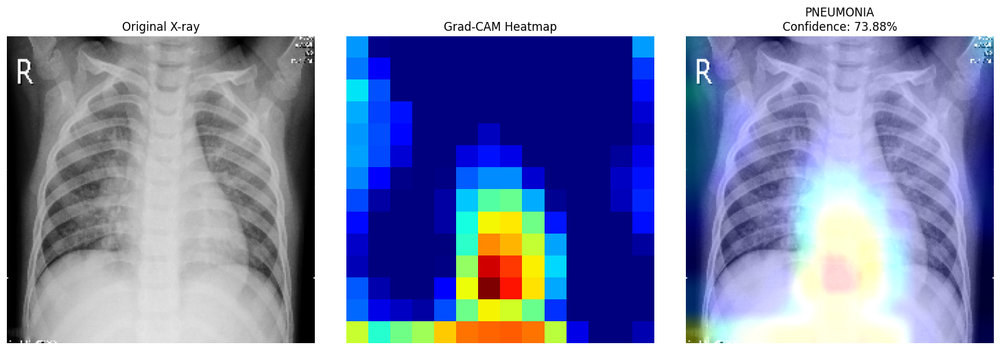


Image 7/10
/content/extracted_images/chest_xray/test/PNEUMONIA/person127_bacteria_604.jpeg


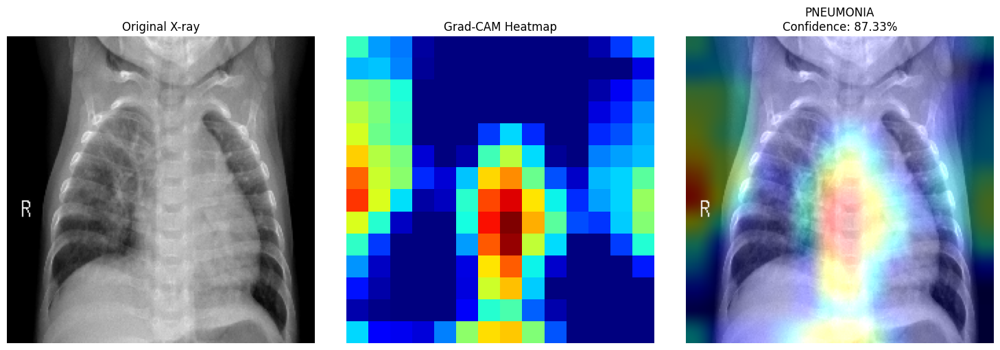


Image 8/10
/content/extracted_images/chest_xray/test/PNEUMONIA/person11_virus_38.jpeg


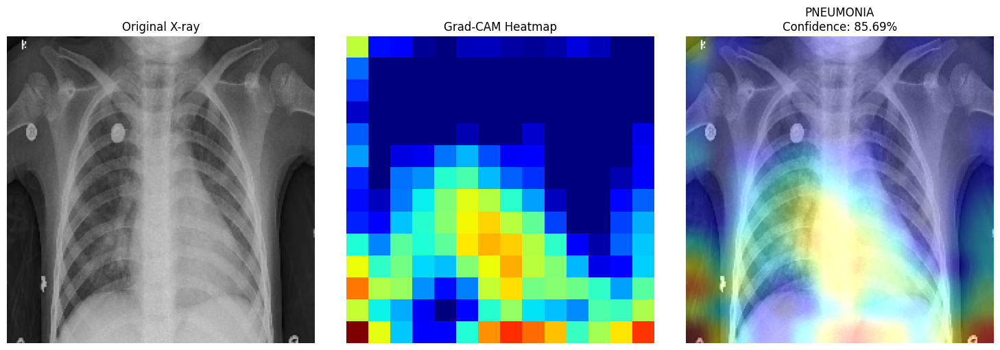


Image 9/10
/content/extracted_images/chest_xray/test/PNEUMONIA/person119_bacteria_567.jpeg


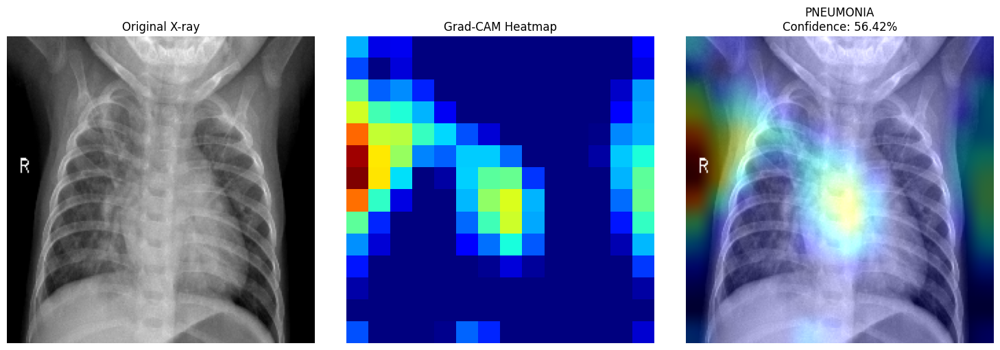


Image 10/10
/content/extracted_images/chest_xray/test/PNEUMONIA/person128_bacteria_606.jpeg


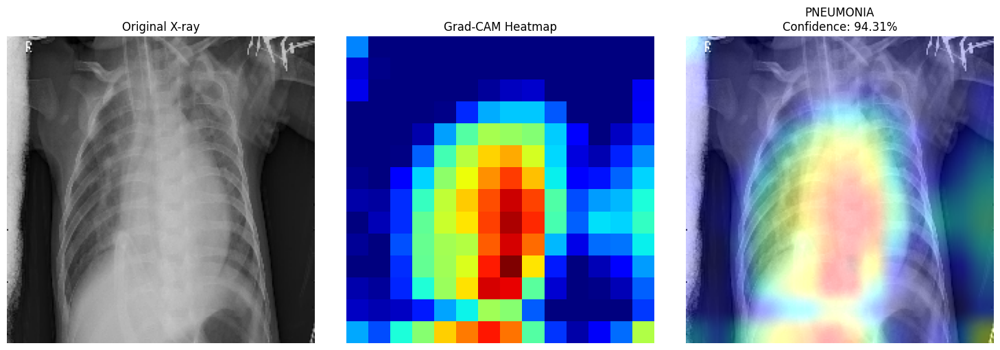

In [ ]:
for i, image_path in enumerate(
    selected_images
):

    print(
        f"\nImage {i+1}/10"
    )

    print(
        image_path
    )

    display_gradcam(
        image_path,
        vgg_model,
        last_conv_layer_name
    )

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Layer


class MAMPooling(Layer):

    def __init__(self, **kwargs):
        super(MAMPooling, self).__init__(**kwargs)

    def build(self, input_shape):

        channels = input_shape[-1]

        # Attention weights
        self.attention_conv = tf.keras.layers.Conv2D(
            filters=1,
            kernel_size=1,
            padding="same",
            activation="sigmoid"
        )

        super(MAMPooling, self).build(input_shape)

    def call(self, inputs):

        # Generate attention map
        attention = self.attention_conv(inputs)

        # Apply attention
        weighted_features = inputs * attention

        # Average pooling
        avg_pool = tf.reduce_mean(
            weighted_features,
            axis=[1, 2]
        )

        # Max pooling
        max_pool = tf.reduce_max(
            weighted_features,
            axis=[1, 2]
        )

        # Combine
        output = tf.concat(
            [avg_pool, max_pool],
            axis=-1
        )

        return output

In [ ]:
import tensorflow as tf

from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import (
    Conv2D,
    BatchNormalization,
    Activation,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model

In [ ]:
class MAMPooling(tf.keras.layers.Layer):

    def __init__(self, **kwargs):
        super(MAMPooling, self).__init__(**kwargs)

    def build(self, input_shape):

        self.attention_conv = Conv2D(
            filters=1,
            kernel_size=1,
            padding="same",
            activation="sigmoid"
        )

        super().build(input_shape)

    def call(self, inputs):

        attention = self.attention_conv(inputs)

        weighted_features = inputs * attention

        avg_pool = tf.reduce_mean(
            weighted_features,
            axis=[1, 2]
        )

        max_pool = tf.reduce_max(
            weighted_features,
            axis=[1, 2]
        )

        return tf.concat(
            [avg_pool, max_pool],
            axis=-1
        )

In [ ]:
base_model_A = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_A.trainable = False

x = base_model_A.output

# Extra Layer 1
x = Conv2D(
    256,
    (3, 3),
    padding="same",
    activation="relu"
)(x)

# Extra Layer 2
x = Conv2D(
    128,
    (3, 3),
    padding="same",
    activation="relu"
)(x)

# Extra Layer 3
x = Conv2D(
    64,
    (3, 3),
    padding="same",
    activation="relu"
)(x)

# MAM Pooling
x = MAMPooling()(x)

x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.5)(x)

output = Dense(
    1,
    activation="sigmoid"
)(x)

model_A = Model(
    inputs=base_model_A.input,
    outputs=output
)

model_A.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model_A.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling (MAMPooling)        │ (None, 128)            │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             

 Total params: 16,280,130 (62.10 MB)

 Trainable params: 1,565,442 (5.97 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history_A = model_A.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 137s 996ms/step - accuracy: 0.8534 - loss: 0.3240 - precision: 0.8616 - recall: 0.9559 - val_accuracy: 0.9340 - val_loss: 0.1673 - val_precision: 0.9657 - val_recall: 0.9446
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 124s 951ms/step - accuracy: 0.9312 - loss: 0.1760 - precision: 0.9569 - recall: 0.9501 - val_accuracy: 0.9359 - val_loss: 0.1583 - val_precision: 0.9850 - val_recall: 0.9278
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 125s 953ms/step - accuracy: 0.9463 - loss: 0.1475 - precision: 0.9676 - recall: 0.9598 - val_accuracy: 0.9407 - val_loss: 0.1297 - val_precision: 0.9589 - val_recall: 0.9613
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 122s 932ms/step - accuracy: 0.9565 - loss: 0.1263 - precision: 0.9725 - recall: 0.9688 - val_accuracy: 0.9550 - val_loss: 0.1122 - val_precision: 0.9815 - val_recall: 0.9575
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 124s 945ms/step - accuracy: 0.9529 - loss: 0.1171 - precision: 0.9700 - recall: 0.9665 - val_accuracy: 0

In [ ]:
loss, accuracy, precision, recall = model_A.evaluate(test_generator)
print("Loss: ", loss)
print("Accuracy: ", accuracy)
print("Precision: ", precision)
print("Recall: ", recall)

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 271ms/step - accuracy: 0.8766 - loss: 0.3990 - precision: 0.8410 - recall: 0.9897
Loss:  0.3990470767021179
Accuracy:  0.8766025900840759
Precision:  0.8409585952758789
Recall:  0.9897435903549194


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

def evaluate_model(model, generator, model_name):

    generator.reset()

    # Prediction probability
    y_prob = model.predict(
        generator,
        verbose=1
    ).ravel()

    # Binary prediction
    y_pred = (y_prob >= 0.5).astype(int)

    # True labels
    y_true = generator.classes

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    # Metrics
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1 Score": f1,
        "AUC": auc
    }

In [ ]:
result_A = evaluate_model(
    model_A,
    test_generator,
    "Model A"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 317ms/step


In [ ]:
from tensorflow.keras.layers import Flatten

In [ ]:
base_model_B = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_B.trainable = False

x = base_model_B.output

# MAM Pooling
x = MAMPooling()(x)

# Flatten
x = Flatten()(x)

# Extra Dense Layer 1
x = Dense(
    512,
    activation="relu"
)(x)

x = Dropout(0.5)(x)

# Extra Dense Layer 2
x = Dense(
    256,
    activation="relu"
)(x)

x = Dropout(0.4)(x)

# Extra Dense Layer 3
x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

# Output
output = Dense(
    1,
    activation="sigmoid"
)(x)

model_B = Model(
    inputs=base_model_B.input,
    outputs=output
)

model_B.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model_B.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_1 (MAMPooling)      │ (None, 1024)           │           513 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             

 Total params: 15,404,354 (58.76 MB)

 Trainable params: 689,666 (2.63 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
history_B = model_B.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.7597 - loss: 0.5133 - precision: 0.7739 - recall: 0.9553 - val_accuracy: 0.8957 - val_loss: 0.3503 - val_precision: 0.9537 - val_recall: 0.9034
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 127s 969ms/step - accuracy: 0.8562 - loss: 0.3282 - precision: 0.8813 - recall: 0.9318 - val_accuracy: 0.9053 - val_loss: 0.2220 - val_precision: 0.9593 - val_recall: 0.9111
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 122s 931ms/step - accuracy: 0.8956 - loss: 0.2495 - precision: 0.9243 - recall: 0.9360 - val_accuracy: 0.9167 - val_loss: 0.2004 - val_precision: 0.9805 - val_recall: 0.9059
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 141s 921ms/step - accuracy: 0.9128 - loss: 0.2199 - precision: 0.9383 - recall: 0.9446 - val_accuracy: 0.9282 - val_loss: 0.1778 - val_precision: 0.9756 - val_recall: 0.9265
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 124s 951ms/step - accuracy: 0.9209 - loss: 0.2013 - precision: 0.9463 - recall: 0.9472 - val_accuracy: 0.93

In [ ]:
loss, accuracy, precision, recall = model_B.evaluate(test_generator)
print("Loss: ", loss)
print("Accuracy: ", accuracy)
print("Precision: ", precision)
print("Recall: ", recall)

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 285ms/step - accuracy: 0.8958 - loss: 0.3212 - precision: 0.8824 - recall: 0.9615
Loss:  0.32117050886154175
Accuracy:  0.8958333134651184
Precision:  0.8823529481887817
Recall:  0.9615384340286255


accuracy comparison

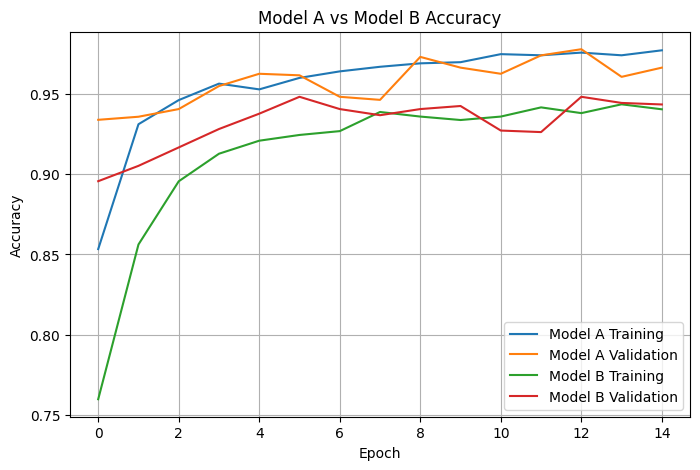

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history_A.history["accuracy"],
    label="Model A Training"
)

plt.plot(
    history_A.history["val_accuracy"],
    label="Model A Validation"
)

plt.plot(
    history_B.history["accuracy"],
    label="Model B Training"
)

plt.plot(
    history_B.history["val_accuracy"],
    label="Model B Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Model A vs Model B Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()

loss comparison

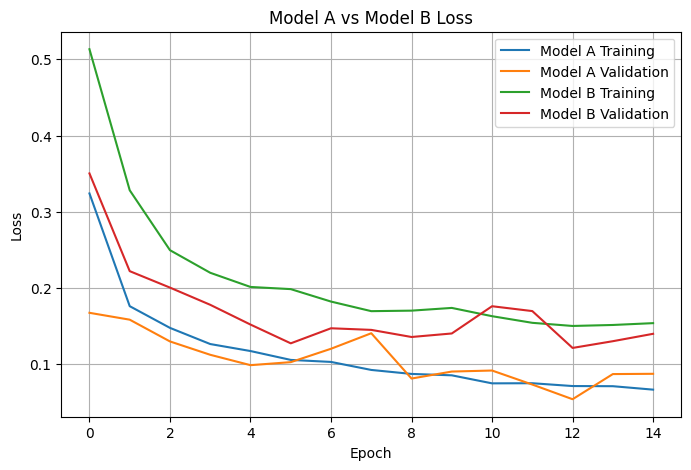

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history_A.history["loss"],
    label="Model A Training"
)

plt.plot(
    history_A.history["val_loss"],
    label="Model A Validation"
)

plt.plot(
    history_B.history["loss"],
    label="Model B Training"
)

plt.plot(
    history_B.history["val_loss"],
    label="Model B Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Model A vs Model B Loss"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
                    VGG16
                      │
              ┌───────┴───────┐
              │               │
           Model A          Model B
              │               │
       3 Conv2D layers       MAM
              │               │
             MAM            Flatten
              │               │
        Dense + Dropout     Dense 512
              │             Dense 256
          Output            Dense 128
                              │
                           Output

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

def evaluate_model(model, generator, model_name):

    generator.reset()

    # Prediction probability
    y_prob = model.predict(
        generator,
        verbose=1
    ).ravel()

    # Binary prediction
    y_pred = (y_prob >= 0.5).astype(int)

    # True labels
    y_true = generator.classes

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    # Metrics
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1 Score": f1,
        "AUC": auc
    }

In [ ]:
result_A = evaluate_model(
    model_A,
    test_generator,
    "Model A"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 316ms/step


In [ ]:
result_B = evaluate_model(
    model_B,
    test_generator,
    "Model B"
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 273ms/step


In [ ]:
results = pd.DataFrame([
    result_A,
    result_B
])

results

,Model,Accuracy,Precision,Sensitivity,Specificity,F1 Score,AUC
0,Model A,0.876603,0.840959,0.989744,0.688034,0.909305,0.970721
1,Model B,0.895833,0.882353,0.961538,0.786325,0.920245,0.947282


In [ ]:
percentage_results = results.copy()

metrics = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1 Score",
    "AUC"
]

percentage_results[metrics] = (
    percentage_results[metrics] * 100
).round(2)

percentage_results

,Model,Accuracy,Precision,Sensitivity,Specificity,F1 Score,AUC
0,Model A,87.66,84.10,98.97,68.80,90.93,97.07
1,Model B,89.58,88.24,96.15,78.63,92.02,94.73


In [ ]:
results["Balanced Score"] = (
    results["Sensitivity"] +
    results["Specificity"] +
    results["F1 Score"] +
    results["AUC"]
) / 4

In [ ]:
results = results.sort_values(
    "Balanced Score",
    ascending=False
)

print(results)

     Model  Accuracy  Precision  Sensitivity  Specificity  F1 Score       AUC  \
1  Model B  0.895833   0.882353     0.961538     0.786325  0.920245  0.947282   
0  Model A  0.876603   0.840959     0.989744     0.688034  0.909305  0.970721   

   Balanced Score  
1        0.903848  
0        0.889451  


In [ ]:
best_model_name = results.iloc[0]["Model"]

print(
    "BEST MODEL:",
    best_model_name
)

BEST MODEL: Model B


In [ ]:
model_dict = {
    "Model A": model_A,
    "Model B": model_B
}

best_model = model_dict[
    best_model_name
]

print(
    "Selected:",
    best_model_name
)

Selected: Model B


20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 236ms/step


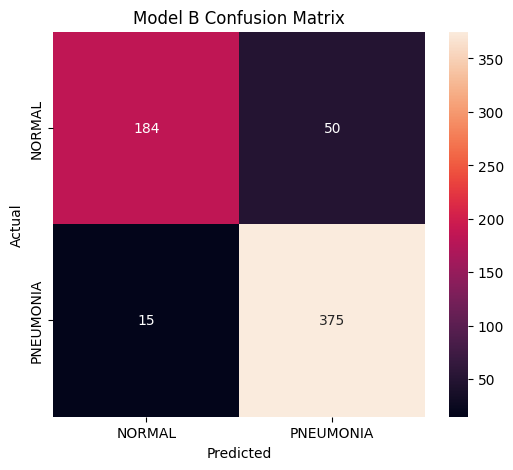

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

test_generator.reset()

y_prob = best_model.predict(
    test_generator,
    verbose=1
).ravel()

y_pred = (
    y_prob >= 0.5
).astype(int)

y_true = test_generator.classes

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    f"{best_model_name} Confusion Matrix"
)

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.92      0.79      0.85       234
   PNEUMONIA       0.88      0.96      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.87      0.89       624
weighted avg       0.90      0.90      0.89       624



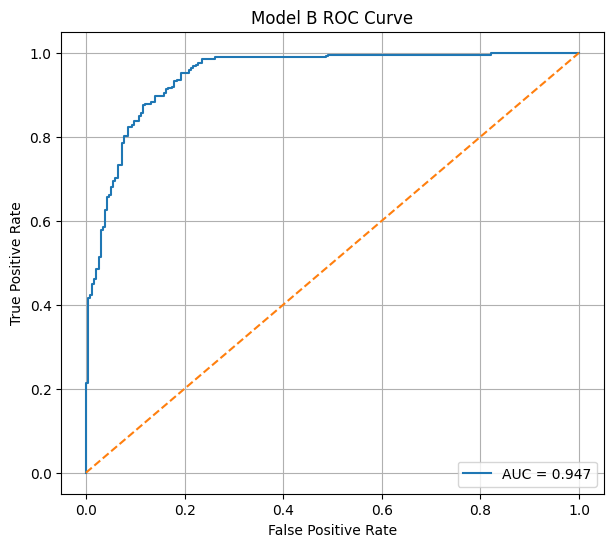

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

auc_value = roc_auc_score(
    y_true,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_value:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"{best_model_name} ROC Curve"
)

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
GAN Synthetic Images
        ↓
Augmented Training Dataset
        ↓
VGG16
        ↓
MAM Pooling
        ↓
       ┌───────────────┐
       │               │
    Model A         Model B
   3 Conv2D        Flatten
      ↓            3 Dense
     MAM               ↓
      ↓              Output
   Output
       │               │
       └───────┬───────┘
               ↓
       Test Evaluation
               ↓
 Accuracy / Precision
 Sensitivity / Specificity
 F1 / AUC
               ↓
          BEST MODEL
               ↓
            Grad-CAM

In [ ]:
print("Best Model:", best_model_name)
best_model.summary()

Best Model: Model B


Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_1 (MAMPooling)      │ (None, 1024)           │           513 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             

 Total params: 16,783,688 (64.02 MB)

 Trainable params: 689,666 (2.63 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 1,379,334 (5.26 MB)

In [ ]:
import os

BEST_MODEL_PATH = "/content/drive/MyDrive/best_chest_xray_model.keras"

best_model.save(BEST_MODEL_PATH)

print("Best Model:", best_model_name)
print("Model saved successfully!")
print("Saved at:", BEST_MODEL_PATH)

Best Model: Model B
Model saved successfully!
Saved at: /content/drive/MyDrive/best_chest_xray_model.keras


In [ ]:
last_conv_layer_name = "block5_conv3"

print(best_model.get_layer(last_conv_layer_name))

<Conv2D name=block5_conv3, built=True>


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model


def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name
):

    grad_model = Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(
                last_conv_layer_name
            ).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        prediction = predictions[:, 0]

    grads = tape.gradient(
        prediction,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]

    pooled_grads = pooled_grads[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    if max_value != 0:
        heatmap /= max_value

    return heatmap.numpy()

In [ ]:
def load_xray(image_path):

    img = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(
        img
    )

    # VGG16 input
    img_array = img_array / 255.0

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    return img, img_array

In [ ]:
def display_gradcam(
    image_path,
    model,
    last_conv_layer_name
):

    original_img, img_array = load_xray(
        image_path
    )

    # Prediction
    probability = model.predict(
        img_array,
        verbose=0
    )[0][0]

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        img_array,
        model,
        last_conv_layer_name
    )

    # Convert heatmap to 0-255
    heatmap_uint8 = np.uint8(
        255 * heatmap
    )

    # Resize heatmap
    heatmap_resized = tf.image.resize(
        heatmap_uint8[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Prediction
    if probability >= 0.5:

        predicted_class = "PNEUMONIA"
        confidence = probability * 100

    else:

        predicted_class = "NORMAL"
        confidence = (1 - probability) * 100

    # Plot
    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        original_img,
        cmap="gray"
    )

    plt.title(
        "Original X-ray"
    )

    plt.axis("off")

    # Heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        heatmap_resized,
        cmap="jet"
    )

    plt.title(
        "Grad-CAM Heatmap"
    )

    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)

    plt.imshow(
        original_img,
        cmap="gray"
    )

    plt.imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.4
    )

    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

In [ ]:
import os

test_path = "/content/extracted_images/chest_xray/test"

normal_path = os.path.join(
    test_path,
    "NORMAL"
)

pneumonia_path = os.path.join(
    test_path,
    "PNEUMONIA"
)

In [ ]:
normal_images = [
    os.path.join(
        normal_path,
        f
    )
    for f in os.listdir(normal_path)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

pneumonia_images = [
    os.path.join(
        pneumonia_path,
        f
    )
    for f in os.listdir(pneumonia_path)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

In [ ]:
selected_images = (
    normal_images[:5]
    + pneumonia_images[:5]
)

print(
    "Selected images:",
    len(selected_images)
)

Selected images: 10


========== Image 1/10 ==========
Actual: NORMAL


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_726']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


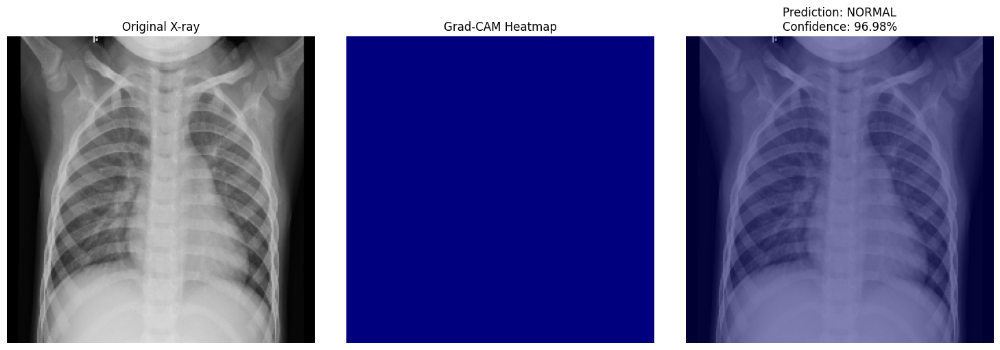

========== Image 2/10 ==========
Actual: NORMAL


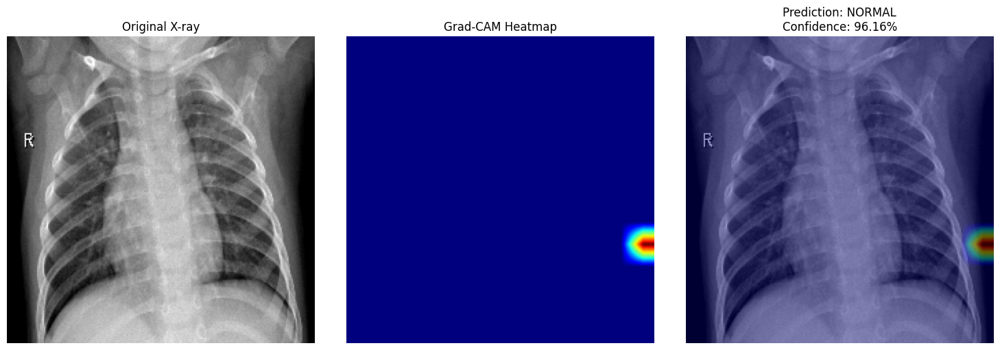

========== Image 3/10 ==========
Actual: NORMAL


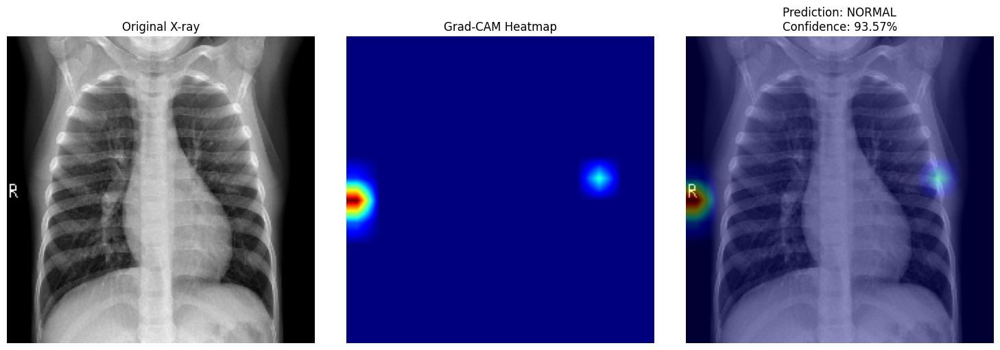

========== Image 4/10 ==========
Actual: NORMAL


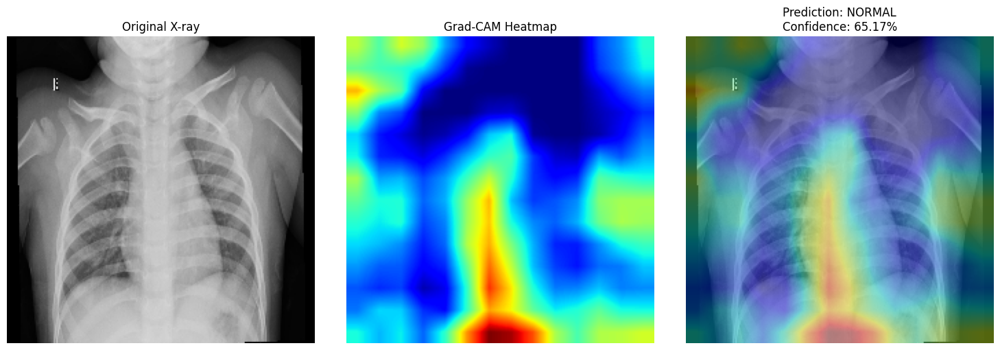

========== Image 5/10 ==========
Actual: NORMAL


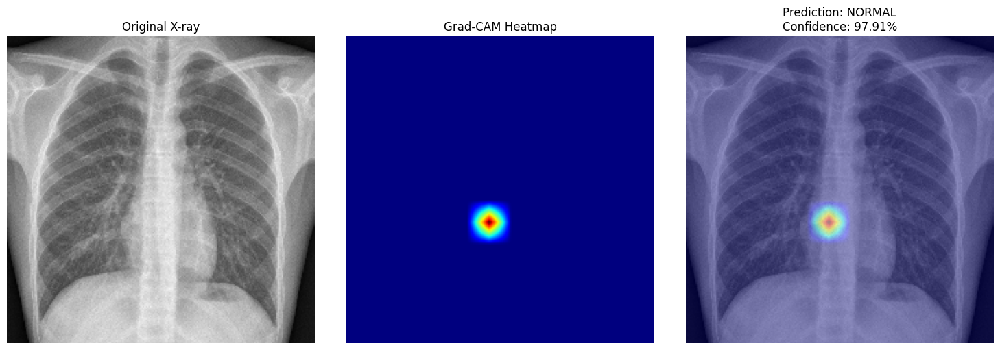

========== Image 6/10 ==========
Actual: PNEUMONIA


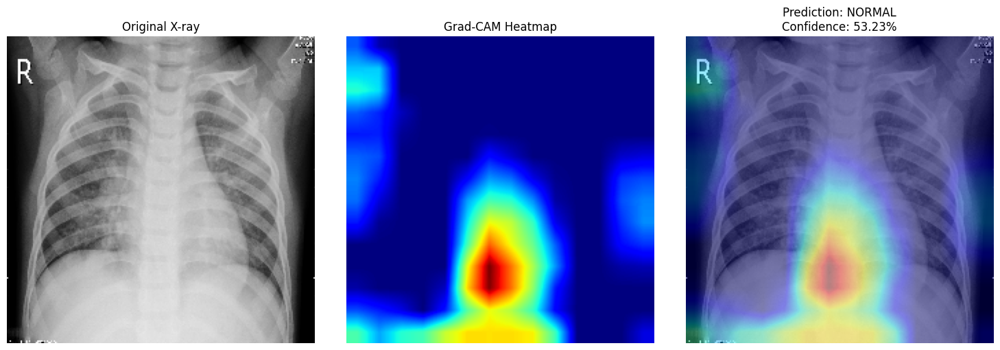

========== Image 7/10 ==========
Actual: PNEUMONIA


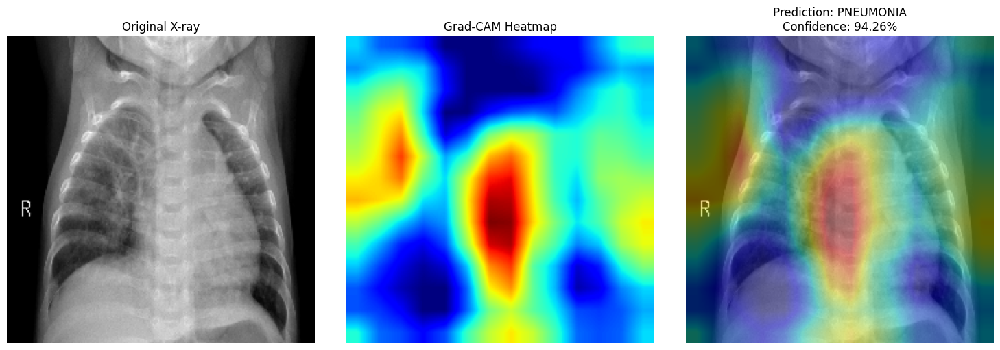

========== Image 8/10 ==========
Actual: PNEUMONIA


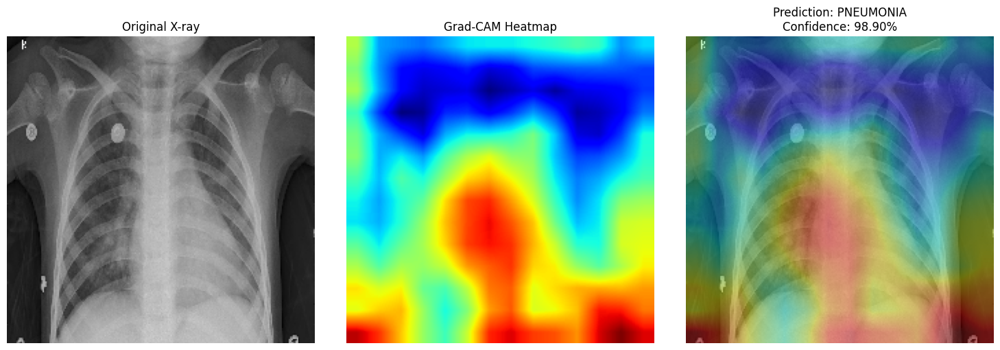

========== Image 9/10 ==========
Actual: PNEUMONIA


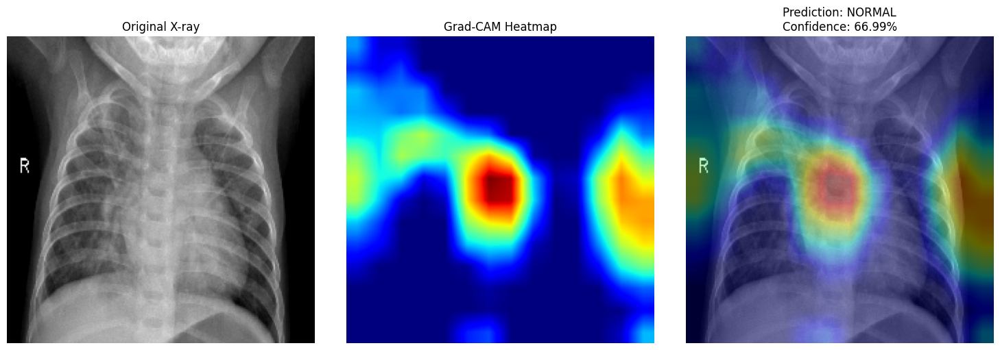

========== Image 10/10 ==========
Actual: PNEUMONIA


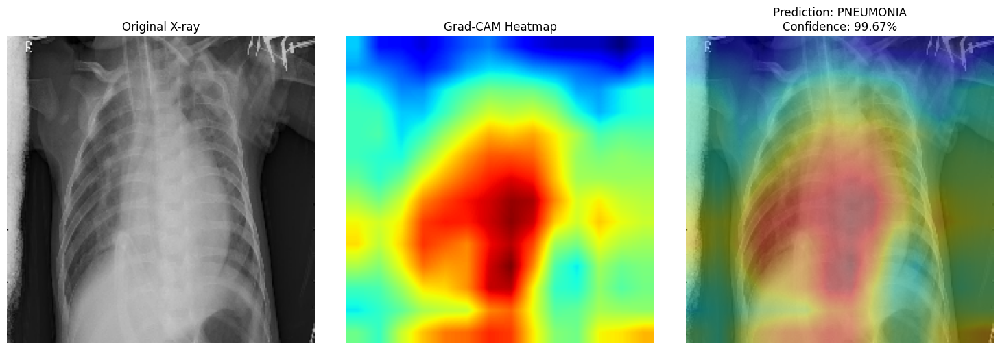

In [ ]:
for i, image_path in enumerate(
    selected_images
):

    print(
        f"========== Image {i+1}/10 =========="
    )

    print(
        "Actual:",
        "NORMAL"
        if i < 5
        else "PNEUMONIA"
    )

    display_gradcam(
        image_path,
        best_model,
        last_conv_layer_name
    )

In [ ]:
Original X-ray
      ↓
Grad-CAM Heatmap
      ↓
Heatmap + X-ray
      ↓
Prediction + Confidence

In [ ]:
import os

BEST_MODEL_PATH = "/content/drive/MyDrive/best_chest_xray_model.keras"

best_model.save(BEST_MODEL_PATH)

print("Best Model:", best_model_name)
print("Model saved successfully!")
print("Saved at:", BEST_MODEL_PATH)

Best Model: Model B
Model saved successfully!
Saved at: /content/drive/MyDrive/best_chest_xray_model.keras


In [ ]:
print(
    "File exists:",
    os.path.exists(BEST_MODEL_PATH)
)

File exists: True


In [ ]:
from tensorflow.keras.models import load_model

loaded_model = load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "MAMPooling": MAMPooling
    }
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
loaded_model.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_1 (MAMPooling)      │ (None, 1024)           │           513 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             

 Total params: 16,783,688 (64.02 MB)

 Trainable params: 689,666 (2.63 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 1,379,334 (5.26 MB)

In [ ]:
BEST_MODEL_PATH = "/content/drive/MyDrive/best_chest_xray_model.keras"

best_model.save(BEST_MODEL_PATH)

print("Model saved:", BEST_MODEL_PATH)

Model saved: /content/drive/MyDrive/best_chest_xray_model.keras


In [ ]:
import os

print(os.path.exists(BEST_MODEL_PATH))

True


In [ ]:
!pip install fastapi uvicorn python-multipart anthropic nest-asyncio pyngrok -q

In [ ]:
%%writefile app.py

import os
import numpy as np
import tensorflow as tf

from fastapi import FastAPI, UploadFile, File
from fastapi.middleware.cors import CORSMiddleware

from PIL import Image

import anthropic


# ------------------------------------------------
# CONFIG
# ------------------------------------------------

MODEL_PATH = "/content/drive/MyDrive/best_chest_xray_model.keras"

ANTHROPIC_API_KEY = os.environ.get(
    "ANTHROPIC_API_KEY"
)


# ------------------------------------------------
# LOAD MODEL
# ------------------------------------------------

model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "MAMPooling": MAMPooling
    }
)


# ------------------------------------------------
# FASTAPI
# ------------------------------------------------

app = FastAPI(
    title="Chest X-ray Pneumonia AI API"
)


app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"]
)


# ------------------------------------------------
# IMAGE PREPROCESSING
# ------------------------------------------------

def preprocess_image(image):

    image = image.convert("RGB")

    image = image.resize(
        (224, 224)
    )

    image = np.array(
        image
    ).astype(
        "float32"
    )

    image = image / 255.0

    image = np.expand_dims(
        image,
        axis=0
    )

    return image


# ------------------------------------------------
# PREDICTION
# ------------------------------------------------

def predict_xray(image):

    img = preprocess_image(
        image
    )

    probability = model.predict(
        img,
        verbose=0
    )[0][0]

    if probability >= 0.5:

        prediction = "PNEUMONIA"
        confidence = probability

    else:

        prediction = "NORMAL"
        confidence = 1 - probability

    return prediction, float(confidence)


# ------------------------------------------------
# PREDICT API
# ------------------------------------------------

@app.post("/predict")
async def predict(
    file: UploadFile = File(...)
):

    image_bytes = await file.read()

    import io

    image = Image.open(
        io.BytesIO(image_bytes)
    )

    prediction, confidence = predict_xray(
        image
    )

    return {
        "prediction": prediction,
        "confidence": round(
            confidence * 100,
            2
        )
    }


# ------------------------------------------------
# CHAT API
# ------------------------------------------------

@app.post("/chat")
async def chat(
    message: str,
    prediction: str = "UNKNOWN",
    confidence: float = 0
):

    if not ANTHROPIC_API_KEY:

        return {
            "error":
            "ANTHROPIC_API_KEY is not configured."
        }

    client = anthropic.Anthropic(
        api_key=ANTHROPIC_API_KEY
    )

    prompt = f"""
You are an educational chest X-ray AI assistant.

The image classification model produced:

Prediction: {prediction}
Confidence: {confidence}%

User question:
{message}

Explain the model output clearly in simple language.

Important:
- Do not claim that the AI prediction is a medical diagnosis.
- Do not prescribe medicines.
- Do not recommend treatment.
- Explain that a qualified healthcare professional/radiologist
  should interpret the chest X-ray.
"""

    response = client.messages.create(
        model="claude-sonnet-4-6",
        max_tokens=500,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ]
    )

    answer = response.content[0].text

    return {
        "answer": answer
    }

Overwriting app.py


In [ ]:
import nest_asyncio
import uvicorn

nest_asyncio.apply()

In [ ]:
import threading

def run_api():

    uvicorn.run(
        "app:app",
        host="0.0.0.0",
        port=8000
    )

thread = threading.Thread(
    target=run_api,
    daemon=True
)

thread.start()

In [ ]:
import os

os.environ["ANTHROPIC_API_KEY"] = "YOUR_API_KEY"

In [ ]:
!pip install streamlit requests -q

In [ ]:
%%writefile streamlit_app.py

import streamlit as st
import requests


st.set_page_config(
    page_title="Chest X-ray AI Assistant",
    page_icon="🩻",
    layout="centered"
)


st.title(
    "🩻 Chest X-ray Pneumonia AI Assistant"
)

st.write(
    "Upload a chest X-ray image for AI classification."
)


API_URL = "YOUR_FASTAPI_URL"


uploaded_file = st.file_uploader(
    "Upload Chest X-ray",
    type=[
        "jpg",
        "jpeg",
        "png"
    ]
)


if uploaded_file:

    st.image(
        uploaded_file,
        caption="Uploaded Chest X-ray",
        use_container_width=True
    )

    if st.button("Predict"):

        files = {
            "file": (
                uploaded_file.name,
                uploaded_file.getvalue(),
                uploaded_file.type
            )
        }

        response = requests.post(
            f"{API_URL}/predict",
            files=files
        )

        if response.status_code == 200:

            result = response.json()

            prediction = result[
                "prediction"
            ]

            confidence = result[
                "confidence"
            ]

            st.subheader(
                f"Prediction: {prediction}"
            )

            st.write(
                f"Confidence: {confidence:.2f}%"
            )

            st.session_state[
                "prediction"
            ] = prediction

            st.session_state[
                "confidence"
            ] = confidence


# ------------------------------------------------
# CHATBOT
# ------------------------------------------------

st.divider()

st.subheader(
    "💬 Ask about the prediction"
)

message = st.text_input(
    "Ask your question"
)


if st.button("Ask Claude"):

    if message:

        prediction = st.session_state.get(
            "prediction",
            "UNKNOWN"
        )

        confidence = st.session_state.get(
            "confidence",
            0
        )

        response = requests.post(
            f"{API_URL}/chat",
            params={
                "message": message,
                "prediction": prediction,
                "confidence": confidence
            }
        )

        if response.status_code == 200:

            answer = response.json()[
                "answer"
            ]

            st.write(answer)

        else:

            st.error(
                "Chatbot request failed."
            )

Overwriting streamlit_app.py


In [ ]:
!streamlit run streamlit_app.py &>/content/streamlit.log &

In [ ]:
get_ipython().system('pip install tensorflow fastapi uvicorn python-multipart pillow numpy anthropic streamlit requests -q')

In [ ]:
User
 ↓
Streamlit
 ↓
FastAPI /predict
 ↓
VGG16 + MAM
 ↓
Prediction
 ↓
FastAPI /chat
 ↓
Claude
 ↓
Explanation

In [ ]:
BEST_MODEL_PATH = "/content/drive/MyDrive/vgg16_best.keras"

best_model.save(BEST_MODEL_PATH)

print("Model saved:", BEST_MODEL_PATH)

Model saved: /content/drive/MyDrive/vgg16_best.keras


In [ ]:
import os

print(os.path.exists(BEST_MODEL_PATH))

True


FAST API BACKENED

In [ ]:
!pip install fastapi uvicorn python-multipart anthropic nest-asyncio pyngrok -q

In [ ]:
%%writefile app.py

import os
import numpy as np
import tensorflow as tf

from fastapi import FastAPI, UploadFile, File
from fastapi.middleware.cors import CORSMiddleware

from PIL import Image

import anthropic


# ------------------------------------------------
# CONFIG
# ------------------------------------------------

MODEL_PATH = "import os

BEST_MODEL_PATH = "/content/drive/MyDrive/best_chest_xray_model.keras"

best_model.save(BEST_MODEL_PATH)

print("Best Model:", best_model_name)
print("Model saved successfully!")
print("Saved at:", BEST_MODEL_PATH)"

ANTHROPIC_API_KEY = os.environ.get(
    "ANTHROPIC_API_KEY"
)


# ------------------------------------------------
# LOAD MODEL
# ------------------------------------------------

model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "MAMPooling": MAMPooling
    }
)


# ------------------------------------------------
# FASTAPI
# ------------------------------------------------

app = FastAPI(
    title="Chest X-ray Pneumonia AI API"
)


app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"]
)


# ------------------------------------------------
# IMAGE PREPROCESSING
# ------------------------------------------------

def preprocess_image(image):

    image = image.convert("RGB")

    image = image.resize(
        (224, 224)
    )

    image = np.array(
        image
    ).astype(
        "float32"
    )

    image = image / 255.0

    image = np.expand_dims(
        image,
        axis=0
    )

    return image


# ------------------------------------------------
# PREDICTION
# ------------------------------------------------

def predict_xray(image):

    img = preprocess_image(
        image
    )

    probability = model.predict(
        img,
        verbose=0
    )[0][0]

    if probability >= 0.5:

        prediction = "PNEUMONIA"
        confidence = probability

    else:

        prediction = "NORMAL"
        confidence = 1 - probability

    return prediction, float(confidence)


# ------------------------------------------------
# PREDICT API
# ------------------------------------------------

@app.post("/predict")
async def predict(
    file: UploadFile = File(...)
):

    image_bytes = await file.read()

    import io

    image = Image.open(
        io.BytesIO(image_bytes)
    )

    prediction, confidence = predict_xray(
        image
    )

    return {
        "prediction": prediction,
        "confidence": round(
            confidence * 100,
            2
        )
    }


# ------------------------------------------------
# CHAT API
# ------------------------------------------------

@app.post("/chat")
async def chat(
    message: str,
    prediction: str = "UNKNOWN",
    confidence: float = 0
):

    if not ANTHROPIC_API_KEY:

        return {
            "error":
            "ANTHROPIC_API_KEY is not configured."
        }

    client = anthropic.Anthropic(
        api_key=ANTHROPIC_API_KEY
    )

    prompt = f"""
You are an educational chest X-ray AI assistant.

The image classification model produced:

Prediction: {prediction}
Confidence: {confidence}%

User question:
{message}

Explain the model output clearly in simple language.

Important:
- Do not claim that the AI prediction is a medical diagnosis.
- Do not prescribe medicines.
- Do not recommend treatment.
- Explain that a qualified healthcare professional/radiologist
  should interpret the chest X-ray.
"""

    response = client.messages.create(
        model="claude-sonnet-4-6",
        max_tokens=500,
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ]
    )

    answer = response.content[0].text

    return {
        "answer": answer
    }

Overwriting app.py


API RUN

In [ ]:
import nest_asyncio
import uvicorn

nest_asyncio.apply()

In [ ]:
import threading

def run_api():

    uvicorn.run(
        "app:app",
        host="0.0.0.0",
        port=8000
    )

thread = threading.Thread(
    target=run_api,
    daemon=True
)

thread.start()

CLAUDE API

In [ ]:
import os

os.environ["ANTHROPIC_API_KEY"] = "YOUR_API_KEY"

In [ ]:
!pip install streamlit requests -q

STREAMLIT FRONTED

In [ ]:
%%writefile streamlit_app.py

import streamlit as st
import requests


st.set_page_config(
    page_title="Chest X-ray AI Assistant",
    page_icon="🩻",
    layout="centered"
)


st.title(
    "🩻 Chest X-ray Pneumonia AI Assistant"
)

st.write(
    "Upload a chest X-ray image for AI classification."
)


API_URL = "YOUR_FASTAPI_URL"


uploaded_file = st.file_uploader(
    "Upload Chest X-ray",
    type=[
        "jpg",
        "jpeg",
        "png"
    ]
)


if uploaded_file:

    st.image(
        uploaded_file,
        caption="Uploaded Chest X-ray",
        use_container_width=True
    )

    if st.button("Predict"):

        files = {
            "file": (
                uploaded_file.name,
                uploaded_file.getvalue(),
                uploaded_file.type
            )
        }

        response = requests.post(
            f"{API_URL}/predict",
            files=files
        )

        if response.status_code == 200:

            result = response.json()

            prediction = result[
                "prediction"
            ]

            confidence = result[
                "confidence"
            ]

            st.subheader(
                f"Prediction: {prediction}"
            )

            st.write(
                f"Confidence: {confidence:.2f}%"
            )

            st.session_state[
                "prediction"
            ] = prediction

            st.session_state[
                "confidence"
            ] = confidence


# ------------------------------------------------
# CHATBOT
# ------------------------------------------------

st.divider()

st.subheader(
    "💬 Ask about the prediction"
)

message = st.text_input(
    "Ask your question"
)


if st.button("Ask Claude"):

    if message:

        prediction = st.session_state.get(
            "prediction",
            "UNKNOWN"
        )

        confidence = st.session_state.get(
            "confidence",
            0
        )

        response = requests.post(
            f"{API_URL}/chat",
            params={
                "message": message,
                "prediction": prediction,
                "confidence": confidence
            }
        )

        if response.status_code == 200:

            answer = response.json()[
                "answer"
            ]

            st.write(answer)

        else:

            st.error(
                "Chatbot request failed."
            )

Overwriting streamlit_app.py


STREAMLIT RUN

In [ ]:
!streamlit run streamlit_app.py &>/content/streamlit.log &

DEPLOYMENT ARCHITURE

In [ ]:
project/
│
├── app.py
├── streamlit_app.py
├── requirements.txt
├── best_chest_xray_model.keras
└── README.md

SyntaxError: invalid character '│' (U+2502) (4249583165.py, line 2)

REQUIREMENT.TXT

In [ ]:
get_ipython().system('pip install tensorflow fastapi uvicorn python-multipart pillow numpy anthropic streamlit requests -q')

In [ ]:
User
 ↓
Streamlit
 ↓
FastAPI /predict
 ↓
VGG16 + MAM
 ↓
Prediction
 ↓
FastAPI /chat
 ↓
Claude
 ↓
Explanation